# IND320 - Project 4: Data to Decision

- **GitHub repository:** https://github.com/giorgiocrupi/giorgiocrupi-ind320-project1
- **Streamlit app:** [LINK]
- **Video:** [LINK TO BE ADDED]

## Log
*(to be written at the end: what I did, problems and solutions, findings)*

## AI declaration
*(to be written at the end)*

## 1. Currency exchange rates from Norges Bank

Norges Bank publishes official exchange rates through an open SDMX API (no key needed).
A series is selected with a key such as `B.EUR+USD.NOK.SP`:
`B` = business-day frequency, `EUR+USD` = base currencies, `NOK` = quote currency, `SP` = spot rate.

The function below downloads the rates for any period, frequency and set of currencies,
and returns one column per currency with the price of **1 unit in NOK**.

In [2]:
import io
import requests
import pandas as pd
import plotly.express as px

# Base address of the Norges Bank exchange-rate data (EXR = exchange rates).
# {frequency} and {currencies} are filled in by the function.
NB_URL = "https://data.norges-bank.no/api/data/EXR/{frequency}.{currencies}.NOK.SP"


def download_exchange_rates(start_date, end_date, currencies=("EUR", "USD"), frequency="B"):
    """Download exchange rates against NOK from the Norges Bank API.

    start_date, end_date : period to download, as "YYYY-MM-DD" strings
    currencies           : base currencies, e.g. ("EUR", "USD")
    frequency            : "B" = business days, "M" = monthly, "A" = annual

    Returns a DataFrame with one row per date and one column per currency,
    containing the price of 1 unit of the currency in NOK.
    """
    # Build the series key, e.g. "B.EUR+USD.NOK.SP" ("+" selects several currencies at once)
    url = NB_URL.format(frequency=frequency, currencies="+".join(currencies))
    params = {
        "format": "csv",          # plain CSV text instead of the default Excel file
        "startPeriod": start_date,
        "endPeriod": end_date,
        "locale": "en",           # English labels and "." as decimal separator
    }
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()   # stop with a clear error if the API does not answer correctly

    # Read the CSV text. sep=None lets pandas detect the separator (Norges Bank uses ";").
    raw = pd.read_csv(io.StringIO(response.text), sep=None, engine="python")

    # OBS_VALUE is the rate. Replace a possible decimal comma with a dot, then convert to numbers.
    values = pd.to_numeric(raw["OBS_VALUE"].astype(str).str.replace(",", "."), errors="coerce")
    # UNIT_MULT is the power of ten of the unit (0 = per 1 unit, 2 = per 100 units, e.g. JPY).
    # Dividing by 10**UNIT_MULT always gives the price of 1 unit.
    values = values / 10 ** raw["UNIT_MULT"].astype(int)

    # Long table (one row per date and currency) -> wide table (one column per currency)
    rates = (
        pd.DataFrame({
            "date": pd.to_datetime(raw["TIME_PERIOD"]),
            "currency": raw["BASE_CUR"],
            "nok": values.values,
        })
        .pivot(index="date", columns="currency", values="nok")
        .sort_index()
    )
    rates.columns.name = None   # remove the leftover "currency" label above the columns
    return rates

### Test of the function

Daily (business-day) EUR and USD rates for 2024, plus a monthly version of the same period
to show that the frequency can be changed.

In [3]:
# Daily rates (business days only: no values on weekends and Norwegian bank holidays)
rates_daily = download_exchange_rates("2024-01-01", "2024-12-31")
print(f"{len(rates_daily)} business days downloaded")
display(rates_daily.head())

# Monthly averages for the same period, to show the frequency parameter
rates_monthly = download_exchange_rates("2024-01-01", "2024-12-31", frequency="M")
display(rates_monthly)

# Interactive Plotly line chart: hover shows the exact value, drag to zoom
fig = px.line(
    rates_daily,
    labels={"value": "NOK per unit", "date": "Date", "variable": "Currency"},
    title="Exchange rates against NOK (Norges Bank, 2024)",
)
fig.show()

251 business days downloaded


,EUR,USD
date,,
2024-01-02,11.2815,10.2971
2024-01-03,11.3200,10.3672
2024-01-04,11.2845,10.3027
2024-01-05,11.3090,10.3553
2024-01-08,11.3620,10.3800


,EUR,USD
date,,
2024-01-01,11.3501,10.4083
2024-02-01,11.3843,10.5463
2024-03-01,11.5120,10.5857
2024-04-01,11.6828,10.8911
2024-05-01,11.5898,10.7199
2024-06-01,11.4178,10.6125
2024-07-01,11.7160,10.8038
2024-08-01,11.7895,10.7073
2024-09-01,11.7852,10.6121


## 2. Time zones in the four data sources

The forecasting model combines data from NVE (Magasinstatistikk), ENTSO-E, Open-Meteo and
Norges Bank. If the sources use different clocks, values can be shifted by one or two hours
(or even assigned to the wrong week). Norway uses CET (UTC+1) in winter and CEST (UTC+2) in
summer, so one day per year has 23 hours (last Sunday of March) and one has 25 hours
(last Sunday of October).

Each source is checked below with real data.

### 2.1 NVE Magasinstatistikk

The reservoir statistics are weekly and identified by ISO year and ISO week, with no time of day.
The API also returns a date field (`dato_Id`). We check which weekday this date falls on,
to know which day of the week the weekly value refers to.

In [4]:
import sys
sys.path.append("..")   # the notebook is in notebooks/, analysis.py is in the project folder
from analysis import load_reservoirs

reservoirs = load_reservoirs()

# dato_Id = date supplied by NVE; Date = Monday of the ISO week (the convention we used so far)
display(reservoirs[["dato_Id", "iso_aar", "iso_uke", "Date"]].head())

# Which weekday does NVE's own date fall on?
nve_dates = pd.to_datetime(reservoirs["dato_Id"])
print("Weekday of dato_Id:")
print(nve_dates.dt.day_name().value_counts())

,dato_Id,iso_aar,iso_uke,Date
0,2020-11-15,2020,46,2020-11-09
1,2011-08-28,2011,34,2011-08-22
2,1998-07-05,1998,27,1998-06-29
3,2011-03-27,2011,12,2011-03-21
4,2017-11-05,2017,44,2017-10-30


Weekday of dato_Id:
dato_Id
Sunday    14976
Name: count, dtype: int64


### 2.2 Open-Meteo

Open-Meteo returns hourly values in GMT (UTC) unless the `timezone` parameter is given.
We download three days around the switch to summer time (31 March 2024) for one point
(Trondheim), once in GMT and once in `Europe/Oslo`, and compare the timestamps.

In [5]:
OPENMETEO_URL = "https://archive-api.open-meteo.com/v1/archive"


def openmeteo_times(timezone):
    """Download three days of hourly temperature for Trondheim in the given time zone
    and return the timestamps together with the UTC offset reported by the API."""
    params = {
        "latitude": 63.43, "longitude": 10.39,
        "start_date": "2024-03-30", "end_date": "2024-04-01",   # 31 March = switch to summer time
        "hourly": "temperature_2m",
        "timezone": timezone,
    }
    response = requests.get(OPENMETEO_URL, params=params, timeout=60)
    response.raise_for_status()
    data = response.json()
    times = pd.to_datetime(data["hourly"]["time"])
    return times, data["utc_offset_seconds"]


for tz in ["GMT", "Europe/Oslo"]:
    times, offset = openmeteo_times(tz)
    print(f"timezone={tz}: offset reported = {offset / 3600:+.0f} h, {len(times)} values")
    # Number of hourly values per calendar day (a correct local clock has 23 on 31 March)
    print(pd.Series(1, index=times).groupby(times.date).size().to_string(), "\n")

timezone=GMT: offset reported = +0 h, 72 values
2024-03-30    24
2024-03-31    24
2024-04-01    24 

timezone=Europe/Oslo: offset reported = +1 h, 72 values
2024-03-30    24
2024-03-31    24
2024-04-01    24 



### 2.3 ENTSO-E

The ENTSO-E Transparency API works in UTC, and in Project 2 the flows were stored in MongoDB
with UTC timestamps. The example below shows what happens when hourly UTC data is converted
to Norwegian local time: the day of the switch to summer time contains only 23 hours.

In [6]:
# Three days of hourly UTC timestamps, starting at local midnight of 30 March (= 23:00 UTC)
utc_index = pd.date_range("2024-03-29 23:00", "2024-04-01 21:00", freq="h", tz="UTC")
oslo_index = utc_index.tz_convert("Europe/Oslo")   # time-zone aware conversion

print("Hours per local day after conversion to Europe/Oslo:")
print(pd.Series(1, index=oslo_index).groupby(oslo_index.date).size().to_string())
print("\nLocal clock around the switch:", list(oslo_index[25:28].strftime("%d %b %H:%M %Z")))

Hours per local day after conversion to Europe/Oslo:
2024-03-30    24
2024-03-31    23
2024-04-01    24

Local clock around the switch: ['31 Mar 01:00 CET', '31 Mar 03:00 CEST', '31 Mar 04:00 CEST']


### 2.4 Norges Bank

The exchange rates have a date but no time, and are only published on Norwegian business days.
We list the weekdays of 2024 that have no rate: these are Norwegian public holidays.

In [7]:
# All Monday-Friday dates of 2024 ("B" = business days in pandas, i.e. Monday to Friday)
weekdays_2024 = pd.date_range("2024-01-01", "2024-12-31", freq="B")
missing = weekdays_2024.difference(rates_daily.index)

print(f"Weekend days have no rates; {len(missing)} weekdays are also missing:")
print([d.strftime("%a %d %b") for d in missing])

Weekend days have no rates; 11 weekdays are also missing:
['Mon 01 Jan', 'Thu 28 Mar', 'Fri 29 Mar', 'Mon 01 Apr', 'Wed 01 May', 'Thu 09 May', 'Fri 17 May', 'Mon 20 May', 'Tue 24 Dec', 'Wed 25 Dec', 'Thu 26 Dec']


### 2.5 Findings and solution

| Source | Resolution | Time information | Finding |
|---|---|---|---|
| NVE Magasinstatistikk | weekly | ISO year + week, `dato_Id` | `dato_Id` is always the **Sunday** that ends the ISO week, so the filling rate is the status at the end of the week. So far each week was labelled with its **Monday** (`Date`). |
| ENTSO-E | hourly | UTC | Stored in MongoDB in UTC. Converted to Norwegian time, one day per year has 23 hours and one has 25. |
| Open-Meteo | hourly | GMT by default, or `timezone` | With `timezone=Europe/Oslo` the API returns one fixed UTC offset (+1 h) for the whole request and 24 values on 31 March, so values after the switch to summer time are one hour off the real Norwegian clock. |
| Norges Bank | business days | date only | No values on weekends and Norwegian public holidays. |

**Solution used in this project**

1. Download hourly data in **UTC** (ENTSO-E, Open-Meteo with `timezone=UTC`) and convert it with
   pandas `tz_convert("Europe/Oslo")`, which handles summer time correctly.
   `download_weather` in `analysis.py` already works this way.
2. Never mix time-zone aware and naive timestamps: convert to Norwegian local time first,
   then drop the time-zone information.
3. Bring all sources to the **resolution of the target variable** (weekly, as NVE): weeks run
   Monday–Sunday and are labelled with the Monday, as in the `Date` column of the reservoir data.
   The filling rate (measured on the Sunday) is then matched with the weather, flows and
   exchange rates of the same week. Missing days (weekends and holidays for Norges Bank)
   are simply left out of the weekly mean.

The helper function below implements step 2 and 3. It will be used to prepare the inputs
of the forecasting model.

In [8]:
def to_weekly(series, how="mean"):
    """Aggregate a daily or hourly series (or DataFrame) to weeks.

    Weeks run Monday-Sunday and are labelled with the Monday, the same convention as the
    `Date` column of the NVE reservoir data.
    how : "mean" (e.g. temperature, exchange rates) or "sum" (e.g. precipitation, energy)
    """
    s = series.copy()
    # Time-zone aware data (e.g. UTC) -> Norwegian local time (summer time handled by pandas),
    # then drop the time zone so it can be combined with the naive NVE dates
    if s.index.tz is not None:
        s.index = s.index.tz_convert("Europe/Oslo").tz_localize(None)
    # "W-MON" bins end on Mondays; closed/label="left" gives [Monday, next Monday) labelled by Monday
    weekly = s.resample("W-MON", closed="left", label="left")
    return weekly.sum() if how == "sum" else weekly.mean()


# Test: weekly mean of the daily exchange rates (holidays and weekends are just left out)
rates_weekly = to_weekly(rates_daily)
display(rates_weekly.head())

# The week labels are Mondays, the same weekdays as the NVE "Date" column
print("Weekday of the labels:", rates_weekly.index.day_name().unique().tolist())
print("Weekday of NVE Date:  ", reservoirs["Date"].dt.day_name().unique().tolist())

,EUR,USD
date,,
2024-01-01,11.29875,10.330575
2024-01-08,11.31326,10.329660
2024-01-15,11.38740,10.453820
2024-01-22,11.40186,10.473680
2024-01-29,11.34956,10.469500


Weekday of the labels: ['Monday']
Weekday of NVE Date:   ['Monday']


## 3. Forecasting the reservoir filling with River

### 3.1 Weekly dataset

The target is the weekly filling rate (%) of one region from Magasinstatistikk.
Possible exogenous variables (inputs from other data sources):

- **Weather (Open-Meteo, ERA5):** weekly mean temperature, weekly total precipitation and snowfall,
  averaged over 10 random locations in the region.
- **Currency (Norges Bank):** weekly mean EUR/NOK and USD/NOK exchange rates.

**Time resolution:** the filling rate is only published once a week, so all inputs are
aggregated to **weeks** (Monday-Sunday, labelled with the Monday) with `to_weekly`.
A daily or hourly model would need 7 or 168 times more steps without giving more information
about the target, so weekly resolution keeps the model fast without losing performance.

The ENTSO-E flows are not used: they only cover October 2024 - September 2026, which is too short
for a model with a yearly (52-week) season.

In [9]:
from analysis import load_locations, region_id_for, reservoir_series, download_weather

# Weather variables used for forecasting: snowfall and precipitation feed the reservoirs,
# temperature controls when the snow melts
FORECAST_WEATHER = ["temperature_2m", "precipitation", "snowfall"]


def build_weekly_dataset(area_type="EL", area_number=3, start_date="2018-01-01",
                         n_locations=10, cache_dir="../data/weather"):
    """Weekly dataset for one region: filling rate (%), weather and exchange rates.

    area_type, area_number : region in Magasinstatistikk, e.g. ("EL", 3) = NO3
    start_date             : first week of the dataset (a Monday, "YYYY-MM-DD")
    n_locations            : random locations used for the regional weather average
    cache_dir              : folder for a local copy of the weather download
    """
    # 1. Target: weekly filling rate in percent (index = Monday of each ISO week)
    fill = reservoir_series(reservoirs, area_type, area_number).loc[start_date:] * 100

    # 2. End of the period: the last complete week (ending on a Sunday) for which ERA5 weather
    #    is available (ERA5 is published with a delay of about 5 days, so we stay 7 days back)
    end = min(fill.index.max() + pd.Timedelta(days=6),
              pd.Timestamp.today().normalize() - pd.Timedelta(days=7))
    end = end - pd.Timedelta(days=(end.weekday() + 1) % 7)   # go back to the previous Sunday
    end_date = end.strftime("%Y-%m-%d")

    # 3. Weather: hourly regional average (downloaded in UTC, converted to Oslo time),
    #    then weekly mean temperature and weekly total precipitation and snowfall.
    #    batch_size=2 and a 20 s pause keep the download below Open-Meteo's per-minute limit.
    weather = download_weather(
        region_id_for(area_type, area_number), start_date, end_date, load_locations(),
        n_locations=n_locations, variables=FORECAST_WEATHER,
        batch_size=2, pause_seconds=20, cache_dir=cache_dir,
    )
    weather_weekly = pd.concat([
        to_weekly(weather["temperature_2m"]),                          # °C, weekly mean
        to_weekly(weather[["precipitation", "snowfall"]], how="sum"),  # mm and cm, weekly total
    ], axis=1)

    # 4. Exchange rates: weekly mean of the business-day rates
    rates_weekly = (to_weekly(download_exchange_rates(start_date, end_date))
                    .rename(columns={"EUR": "eur_nok", "USD": "usd_nok"}))

    # 5. Put everything side by side (aligned on the Monday labels) and keep complete weeks only
    data = pd.concat([fill.rename("fill_rate"), weather_weekly, rates_weekly], axis=1).dropna()
    data.index.name = "week"
    return data


# Dataset for price area NO3 (Central Norway). The first run downloads about 9 years of
# hourly weather (about 1-2 minutes); later runs read the local copy in data/weather.
data_no3 = build_weekly_dataset("EL", 3)
print(f"{len(data_no3)} weeks: {data_no3.index.min().date()} to {data_no3.index.max().date()}")
display(data_no3.tail())

463 weeks: 2018-01-01 to 2026-11-09


,fill_rate,temperature_2m,precipitation,snowfall,eur_nok,usd_nok
week,,,,,,
2026-10-12,72.494050,7.753669,45.830002,0.119,10.6487,9.50360
2026-10-19,71.764696,8.517056,7.850000,0.000,10.5093,9.37124
2026-10-26,72.014890,8.718163,44.150002,0.007,10.3668,9.29372
2026-11-02,71.870520,6.806853,16.120001,0.000,10.4111,9.28732
2026-11-09,69.723690,3.225217,44.590000,2.898,10.5790,9.50230


### 3.2 Forecasting function (River SNARIMAX)

`SNARIMAX` is River's online version of SARIMAX. It learns one week at a time (`learn_one`)
and forecasts several weeks ahead recursively (`forecast`), using its own predictions as lagged
values for the later weeks (dynamic forecasting).

| Parameter | Meaning |
|---|---|
| `p`, `d`, `q` | autoregressive order (number of past weeks), differencing, moving-average order (past errors) |
| `m`, `sp`, `sd`, `sq` | season length (52 weeks), seasonal AR order, seasonal differencing, seasonal MA order |
| `learning_rate` | step size of the SGD optimiser in the linear regression inside SNARIMAX |
| `history_weeks` | length of the training history |
| `horizon` | number of weeks to forecast |
| `exogenous` | selected exogenous variables (data sources): weather and/or exchange rates |

**Future values of the exogenous variables** are unknown when forecasting, so the function uses
the weekly **climatology** (mean of the same ISO week in the training history) for the weather
variables and the **last known value** for the exchange rates.
The forecast is clipped to 0-100 %, the physical limits of a reservoir.

In [10]:
from river import time_series, preprocessing, linear_model, optim

WEATHER_COLUMNS = ["temperature_2m", "precipitation", "snowfall"]
CURRENCY_COLUMNS = ["eur_nok", "usd_nok"]


def future_exogenous(history, exogenous, future_weeks):
    """Assumed values of the exogenous variables in the forecast weeks.

    Weather  -> climatology: mean of the same ISO week of the year in the training history.
    Currency -> last known value (a simple "no change" assumption).
    Returns one dictionary per future week, the format River expects.
    """
    week_of_year = history.index.isocalendar().week
    rows = []
    for week in future_weeks:
        row = {}
        for col in exogenous:
            if col in WEATHER_COLUMNS:
                value = history.loc[week_of_year == week.isocalendar().week, col].mean()
                if pd.isna(value):              # e.g. ISO week 53, which is rare
                    value = history[col].mean()
            else:
                value = history[col].iloc[-1]
            row[col] = float(value)
        rows.append(row)
    return rows


def forecast_filling(data, history_weeks=260, horizon=13, exogenous=(),
                     p=1, d=0, q=0, m=52, sp=0, sd=1, sq=0,
                     learning_rate=0.01, end=None):
    """Forecast the weekly filling rate (%) of one region with River's SNARIMAX.

    data          : weekly dataset from build_weekly_dataset (column "fill_rate" + exogenous)
    history_weeks : number of weeks used for training (length of history)
    horizon       : number of weeks to forecast
    exogenous     : list of exogenous columns to use (empty = filling rate only)
    p, d, q       : non-seasonal AR order, differencing, MA order
    m, sp, sd, sq : season length, seasonal AR order, seasonal differencing, seasonal MA order
    learning_rate : step size of the SGD optimiser
    end           : last week used for training (default: the last week in the data).
                    Setting it earlier hides the following weeks, so the forecast can be tested.
    Returns a DataFrame indexed by week with the forecast and, if known, the actual value.
    """
    exogenous = list(exogenous)
    end = data.index[-1] if end is None else pd.Timestamp(end)

    # 1. Training history: the last `history_weeks` weeks up to `end`
    history = data.loc[:end].iloc[-history_weeks:]
    if len(history) < 2 * m:
        raise ValueError(f"At least {2 * m} weeks of history are needed (got {len(history)}).")

    # 2. Model: SNARIMAX builds the lagged values (and differences) and passes them, together
    #    with the exogenous variables, to a linear regression trained with SGD.
    #    StandardScaler puts all inputs on the same scale so that SGD treats them equally.
    #    Without differencing the regression predicts the level itself, so its intercept
    #    starts at the mean level; with differencing it predicts changes, which are around 0.
    regressor = preprocessing.StandardScaler() | linear_model.LinearRegression(
        optimizer=optim.SGD(learning_rate),
        intercept_init=0.0 if (d or sd) else float(history["fill_rate"].mean()),
        intercept_lr=0.1,
    )
    model = time_series.SNARIMAX(p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq, regressor=regressor)

    # 3. Online training: one week at a time, as if the data arrived as a stream
    for _, row in history.iterrows():
        x = {col: float(row[col]) for col in exogenous}
        model.learn_one(y=float(row["fill_rate"]), x=x)

    # 4. Dynamic forecast for the next `horizon` weeks (Mondays after `end`)
    future_weeks = pd.date_range(end + pd.Timedelta(weeks=1), periods=horizon, freq="W-MON")
    xs = future_exogenous(history, exogenous, future_weeks)
    predictions = model.forecast(horizon=horizon, xs=xs)

    # 5. Result: forecast clipped to the physical range, plus the actual values when known
    result = pd.DataFrame({"forecast": predictions}, index=future_weeks).clip(0, 100)
    result["actual"] = data["fill_rate"].reindex(future_weeks)
    result.index.name = "week"
    return result

### First test

The last 26 weeks of the data are hidden from the model (`end` = 27 weeks before the last week),
and a 26-week forecast is compared with the actual filling rate, with and without exogenous
variables. The **seasonal naive** forecast ("same week last year") is used as a baseline:
a useful model should have a lower mean absolute error (MAE, in percentage points).

In [11]:
import plotly.graph_objects as go

test_end = data_no3.index[-27]   # train up to here, forecast the following 26 weeks

fc_plain = forecast_filling(data_no3, horizon=26, end=test_end)
fc_exog = forecast_filling(data_no3, horizon=26, end=test_end,
                           exogenous=["temperature_2m", "precipitation", "snowfall"])

# Seasonal naive baseline: the filling rate of the same week one year (52 weeks) earlier
naive = data_no3["fill_rate"].shift(52).reindex(fc_plain.index)


def mae(forecast, actual):
    """Mean absolute error in percentage points."""
    return float((forecast - actual).abs().mean())


print(f"MAE SNARIMAX, no exogenous:     {mae(fc_plain.forecast, fc_plain.actual):.2f} pp")
print(f"MAE SNARIMAX, weather:          {mae(fc_exog.forecast, fc_exog.actual):.2f} pp")
print(f"MAE seasonal naive (baseline):  {mae(naive, fc_plain.actual):.2f} pp")

# Interactive plot: last two years of data and the three forecasts
recent = data_no3["fill_rate"].loc[test_end - pd.Timedelta(weeks=78):]
fig = go.Figure()
fig.add_trace(go.Scatter(x=recent.index, y=recent, name="Actual", line=dict(color="black")))
fig.add_trace(go.Scatter(x=fc_plain.index, y=fc_plain.forecast, name="SNARIMAX"))
fig.add_trace(go.Scatter(x=fc_exog.index, y=fc_exog.forecast, name="SNARIMAX + weather"))
fig.add_trace(go.Scatter(x=naive.index, y=naive, name="Seasonal naive", line=dict(dash="dot")))
fig.add_vline(x=test_end, line_dash="dash", line_color="grey")   # end of the training data
fig.update_layout(title="NO3: 26-week forecast of the filling rate (test on hidden data)",
                  xaxis_title="Week", yaxis_title="Filling rate (%)")
fig.show()

MAE SNARIMAX, no exogenous:     6.05 pp
MAE SNARIMAX, weather:          4.90 pp
MAE seasonal naive (baseline):  24.98 pp


### 3.3 Systematic testing (backtesting and grid search)

One test period is not enough to judge a model. The function is therefore tested by
**backtesting**: 8 forecast origins, 13 weeks apart (covering the last two years and all
seasons). For each origin the following weeks are hidden, a **13-week (3-month)** forecast is
made, and the MAE is computed; the 8 MAEs are averaged.

All combinations of the following settings are tested (144 settings, 1152 forecasts):

- **history length:** 104, 208 and 312 weeks (2, 4 and 6 years)
- **exogenous data sources:** none, weather, currency, weather + currency
- **model structure:** four combinations of `p`, `d`, `sd`, `sq`
- **learning rate:** 0.005, 0.01, 0.03

The computing time per forecast is also measured. The seasonal naive forecast is evaluated on the
same origins as a baseline.

In [13]:
import itertools
import time
import numpy as np

HORIZON_TEST = 13   # 3 months ahead
# 8 forecast origins, 13 weeks apart; the last one leaves exactly 13 known weeks after it
cutoffs = [data_no3.index[-HORIZON_TEST - 1 - 13 * k] for k in range(8)]

EXOG_SETS = {
    "none": [],
    "weather": WEATHER_COLUMNS,
    "currency": CURRENCY_COLUMNS,
    "weather + currency": WEATHER_COLUMNS + CURRENCY_COLUMNS,
}
MODEL_SETS = {
    "AR(1) + seasonal diff": dict(p=1, d=0, sd=1, sq=0),
    "AR(2) + seasonal diff": dict(p=2, d=0, sd=1, sq=0),
    "AR(1) + seasonal diff + seasonal MA(1)": dict(p=1, d=0, sd=1, sq=1),
    "AR(2) + diff, no season": dict(p=2, d=1, sd=0, sq=0),
}
HISTORIES = [104, 208, 312]
LEARNING_RATES = [0.005, 0.01, 0.03]


def backtest(data, cutoffs, horizon, **settings):
    """Average MAE (pp) and average computing time (s) over all forecast origins."""
    errors, seconds = [], []
    for end in cutoffs:
        start = time.perf_counter()
        try:
            fc = forecast_filling(data, horizon=horizon, end=end, **settings)
            errors.append(mae(fc.forecast, fc.actual))
        except (ValueError, OverflowError):
            errors.append(np.nan)          # a setting that fails or diverges gets no score
        seconds.append(time.perf_counter() - start)
    return np.mean(errors), np.mean(seconds)


# Baseline on the same origins: seasonal naive (same week one year earlier)
naive_errors = []
for end in cutoffs:
    weeks = pd.date_range(end + pd.Timedelta(weeks=1), periods=HORIZON_TEST, freq="W-MON")
    naive_errors.append(mae(data_no3["fill_rate"].shift(52).reindex(weeks),
                            data_no3["fill_rate"].reindex(weeks)))
print(f"Seasonal naive baseline: MAE = {np.mean(naive_errors):.2f} pp")

# Grid search over all combinations of the settings
rows = []
combinations = list(itertools.product(HISTORIES, EXOG_SETS, MODEL_SETS, LEARNING_RATES))
for i, (history, exog_name, model_name, lr) in enumerate(combinations, start=1):
    mean_mae, mean_time = backtest(
        data_no3, cutoffs, HORIZON_TEST,
        history_weeks=history, exogenous=EXOG_SETS[exog_name],
        learning_rate=lr, **MODEL_SETS[model_name],
    )
    rows.append({"history_weeks": history, "exogenous": exog_name, "model": model_name,
                 "learning_rate": lr, "MAE": mean_mae, "seconds": mean_time})
    if i % 24 == 0:
        print(f"{i}/{len(combinations)} settings tested")

results = pd.DataFrame(rows).sort_values("MAE")
display(results.head(10).round(3))

Seasonal naive baseline: MAE = 21.47 pp
24/144 settings tested
48/144 settings tested
72/144 settings tested
96/144 settings tested
120/144 settings tested
144/144 settings tested


,history_weeks,exogenous,model,learning_rate,MAE,seconds
98,312,none,AR(1) + seasonal diff,0.03,5.928,0.036
122,312,currency,AR(1) + seasonal diff,0.03,6.036,0.048
26,104,currency,AR(1) + seasonal diff,0.03,6.296,0.026
32,104,currency,AR(1) + seasonal diff + seasonal MA(1),0.03,6.296,0.022
8,104,none,AR(1) + seasonal diff + seasonal MA(1),0.03,6.302,0.040
2,104,none,AR(1) + seasonal diff,0.03,6.302,0.059
52,208,none,AR(2) + seasonal diff,0.01,6.459,0.026
47,104,weather + currency,"AR(2) + diff, no season",0.03,6.517,0.073
101,312,none,AR(2) + seasonal diff,0.03,6.575,0.035
100,312,none,AR(2) + seasonal diff,0.01,6.613,0.035


Average MAE for each value of each setting (averaged over all other settings),
to see which choices matter most:

In [14]:
for setting in ["history_weeks", "exogenous", "model", "learning_rate"]:
    display(results.groupby(setting)[["MAE", "seconds"]].mean().sort_values("MAE").round(3))

,MAE,seconds
history_weeks,,
312,9.190,0.060
208,9.476,0.051
104,9.958,0.048


,MAE,seconds
exogenous,,
weather + currency,9.049,0.070
weather,9.309,0.066
currency,9.870,0.040
none,9.937,0.035


,MAE,seconds
model,,
AR(2) + seasonal diff,8.138,0.051
AR(1) + seasonal diff,8.701,0.054
AR(1) + seasonal diff + seasonal MA(1),9.091,0.052
"AR(2) + diff, no season",12.237,0.054


,MAE,seconds
learning_rate,,
0.030,9.142,0.051
0.010,9.358,0.053
0.005,10.125,0.054


The best settings all use the highest learning rate in the grid (0.03). Because the optimum is at
the edge of the tested range, higher learning rates are checked for the best model structure
(AR(1) + seasonal differencing, 312 weeks of history), with and without exogenous variables.

In [15]:
rows = []
for lr in [0.03, 0.05, 0.1, 0.2]:
    for exog_name in ["none", "weather", "weather + currency"]:
        mean_mae, mean_time = backtest(
            data_no3, cutoffs, HORIZON_TEST,
            history_weeks=312, exogenous=EXOG_SETS[exog_name],
            learning_rate=lr, **MODEL_SETS["AR(1) + seasonal diff"],
        )
        rows.append({"learning_rate": lr, "exogenous": exog_name,
                     "MAE": mean_mae, "seconds": mean_time})

# One row per learning rate, one column per exogenous set
lr_check = pd.DataFrame(rows).pivot(index="learning_rate", columns="exogenous", values="MAE")
display(lr_check.round(3))

exogenous,none,weather,weather + currency
learning_rate,,,
0.03,5.928,7.485,7.106
0.05,6.679,8.444,7.576
0.10,9.513,30.508,47.908
0.20,44.806,47.022,48.528


### 3.4 Findings of the tests

**How the function was tested:** backtesting with 8 forecast origins (13 weeks apart, the last
two years), 13-week forecasts, mean absolute error (MAE) in percentage points; a grid of
144 settings (history length × exogenous variables × model structure × learning rate),
followed by a check of higher learning rates because the best value was at the edge of the grid.

**Experiences and findings (price area NO3):**

- **All tested SNARIMAX settings with a seasonal part beat the seasonal naive baseline by far**
  (best MAE 5.9 pp against 21.5 pp). "Same week last year" works poorly because the level differs
  a lot from year to year (spring 2026 was much lower than spring 2025), while SNARIMAX starts
  from the current level and adds the usual seasonal change.
- **Seasonality is essential:** the model without seasonal differencing is clearly the worst
  (average MAE 12.2 pp). A seasonal moving-average term (`sq=1`) did not help.
- **Longer history is better:** 312 weeks (6 years) gave a lower MAE than 208 or 104 weeks.
- **Exogenous variables help slightly on average but not for the best model.** In future weeks the
  model only knows the weather climatology, not the real weather, so the weather adds little
  information; the exchange rates have no physical link with the reservoirs.
- **Learning rate:** 0.005 learns too slowly; 0.03 is the best; 0.05 is already worse, and
  0.1-0.2 make the online SGD unstable (MAE 10-48 pp), especially with exogenous variables.
- **Time resolution:** with weekly data each forecast takes only 0.02-0.07 s (including training
  on up to 6 years), so the weekly resolution is fast enough for interactive use in Streamlit.

**Default setting used in Streamlit:** 312 weeks of history, no exogenous variables,
AR(1) + seasonal differencing (`p=1, d=0, q=0, sp=0, sd=1, sq=0, m=52`), learning rate 0.03,
horizon 13 weeks. The user can still add exogenous variables and change all parameters.

### 3.5 Forecast of the coming months with the default setting

The model is trained on all data up to the last available week and forecasts the next 13 weeks.

In [16]:
# Best setting from the tests: used as the default in the Streamlit forecasting page
BEST_SETTINGS = dict(history_weeks=312, exogenous=[], p=1, d=0, q=0, m=52,
                     sp=0, sd=1, sq=0, learning_rate=0.03)

future = forecast_filling(data_no3, horizon=13, **BEST_SETTINGS)
display(future[["forecast"]].round(1))

# Last year of data followed by the forecast
recent = data_no3["fill_rate"].iloc[-52:]
fig = go.Figure()
fig.add_trace(go.Scatter(x=recent.index, y=recent, name="Observed", line=dict(color="black")))
fig.add_trace(go.Scatter(x=future.index, y=future.forecast, name="Forecast (13 weeks)",
                         line=dict(dash="dash")))
fig.update_layout(title="NO3: forecast of the filling rate for the coming 3 months",
                  xaxis_title="Week", yaxis_title="Filling rate (%)")
fig.show()

,forecast
week,
2026-11-16,66.8
2026-11-23,64.3
2026-11-30,61.5
2026-12-07,59.5
2026-12-14,58.8
2026-12-21,56.0
2026-12-28,52.1
2027-01-04,47.6
2027-01-11,43.2


**Note:** the forecast follows the usual winter decrease, but it falls faster than in the previous
winter (about 24 % in mid-February, against about 42 % in February 2026). In a dynamic forecast each
predicted week is used as input for the next one, so errors accumulate and the last weeks of the
horizon are much less reliable than the first ones. Confidence intervals (see the bonus exercise)
would show this growing uncertainty.

## 4. Sketch of the new app structure

Before changing the code, the content of the app was organised in the sketch below
(drawn by hand; the text labels in blue were added with help from Claude).

**Structure and navigation**

- The pages are grouped by the **type of task**, and the sidebar menu shows these groups as headers:
  - **Explore:** Home, Map, Reservoir overview, Cross-border flows, Exchange rates
  - **Anomalies:** Reservoir seasonality (STL and spectrogram), SPC outliers, LOF anomalies
  - **Relations + prediction:** Sliding window correlation, Forecast
- The **selected area and time period** are stored in `st.session_state` and shown in the sidebar on
  every page. A click on the map changes the selected area, so all analysis pages follow the same
  selection, while page-specific choices (weather property, lag, model parameters, ...) stay local.
- The old LineChartColumn table is joined with the trend plot in one **Reservoir overview** page.

**New pages**

- **Map:** GeoJSON areas (EL or VASS) coloured by filling rate or a weather property in the chosen
  week; a click selects an area (thicker outline) and

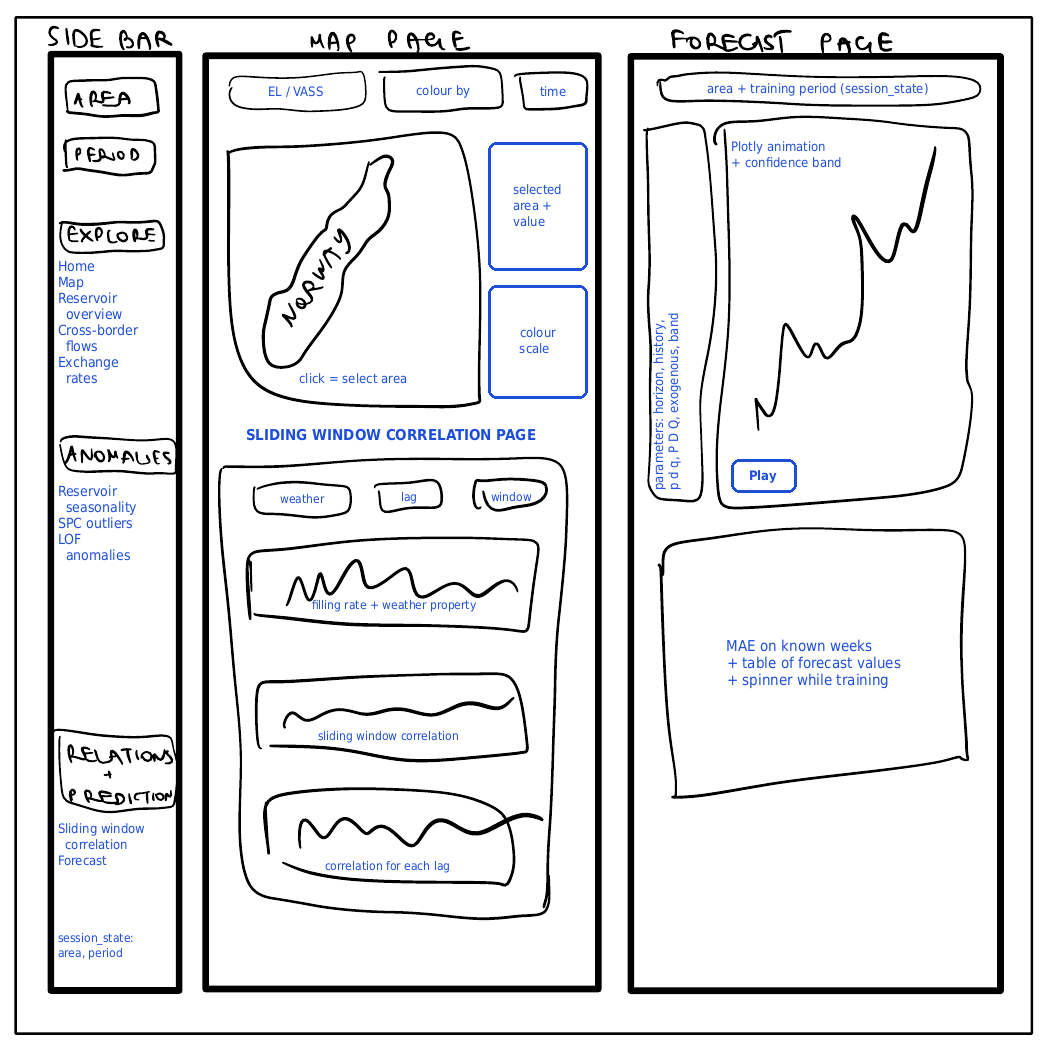

## 5. Shapefiles converted to GeoJSON (for the map in the app)

The interactive map in the Streamlit app needs the outlines of the three types of areas used in
Magasinstatistikk. The NVE Atlas shapefiles from Project 3 are converted to GeoJSON, a single text
file that web maps can read directly:

- **EL:** the five electricity price areas NO1–NO5 (*Budområder* shapefile).
- **VASS:** the four watercourse areas, built by merging the NVE regions with the same rule as in
  Project 3 (VASS1 = RØ + RS, VASS2 = RV, VASS3 = RM, VASS4 = RN).
- **NO:** Norway as a whole, the union of the five price areas.

The geometries are converted from UTM 33N (metres) to longitude/latitude (WGS84), as web maps
require, and simplified with a tolerance of about 500 m. This keeps the files small and the map
fast, without a visible change of the outlines.

areas_EL.geojson: 5 areas, 0.05 MB
areas_NO.geojson: 1 areas, 0.02 MB
areas_VASS.geojson: 4 areas, 0.09 MB


/var/folders/1t/fmkshrbx3y52jxd9mdfbk1140000gn/T/ipykernel_83347/1653143880.py:61: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


NVE region codes: ['RV', 'RM', 'RN', 'RØ', 'RS']
areas_EL.geojson: 5 areas, 0.05 MB
areas_NO.geojson: 1 areas, 0.02 MB
areas_VASS.geojson: 4 areas, 0.09 MB


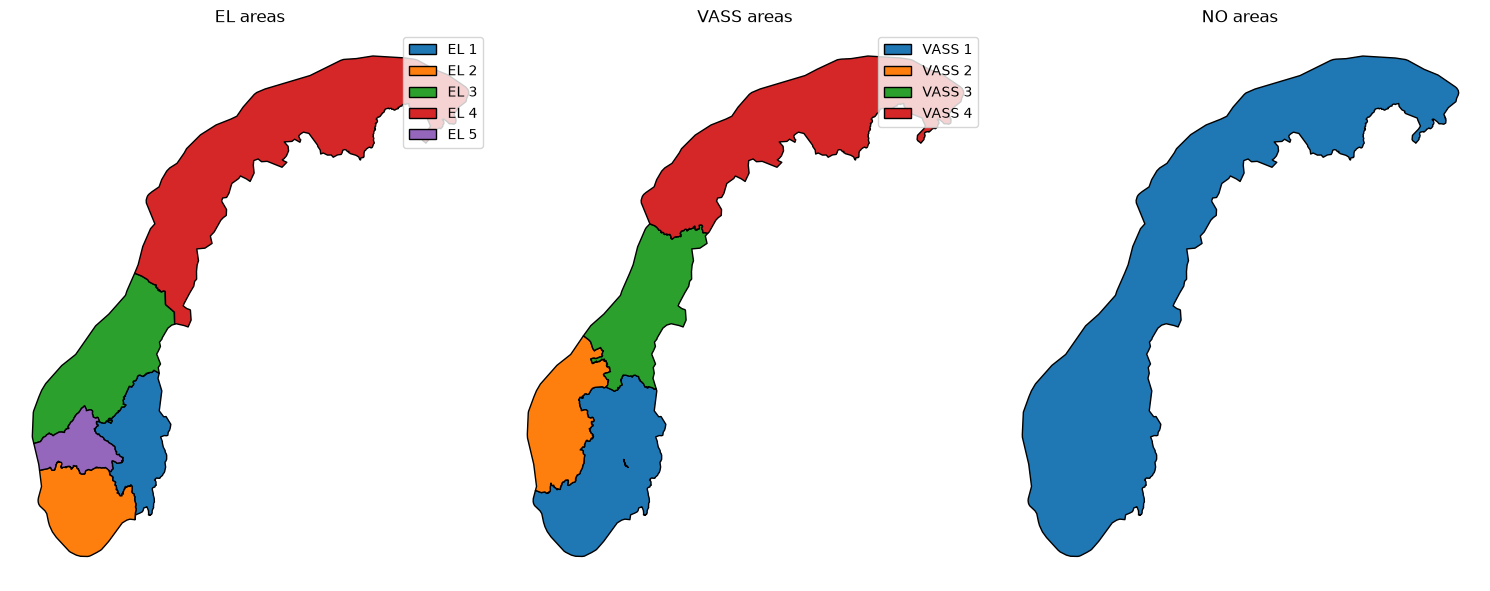

In [21]:
%matplotlib inline
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

SHAPE_DIR = Path("../shapefiles")
SIMPLIFY_METRES = 500   # tolerance of the simplification (in UTM 33N, i.e. metres)

# Same merging rule as in Project 3
VASS_TO_NVE = {1: ["RØ", "RS"], 2: ["RV"], 3: ["RM"], 4: ["RN"]}
NAMES = {
    ("EL", 1): "NO1 – South-East Norway", ("EL", 2): "NO2 – South-West Norway",
    ("EL", 3): "NO3 – Central Norway", ("EL", 4): "NO4 – Northern Norway",
    ("EL", 5): "NO5 – Western Norway",
    ("VASS", 1): "VASS1 – South-East Norway", ("VASS", 2): "VASS2 – Western Norway",
    ("VASS", 3): "VASS3 – Central Norway", ("VASS", 4): "VASS4 – Northern Norway",
    ("NO", 0): "Norway",
}


def read_shapefile(folder):
    """Read the single .shp file in a folder (kept in UTM 33N, metres, for the simplification)."""
    return gpd.read_file(next(Path(folder).glob("*.shp")), encoding="utf-8")


elspot = read_shapefile(SHAPE_DIR / "elspot")
regions = read_shapefile(SHAPE_DIR / "regions")

# Safety check for the Norwegian letter Ø: if the region codes were read with the wrong text
# encoding ('RÃ\x98' instead of 'RØ'), decode them again so that 'RØ' is found below
if not regions["REGION"].isin(["RØ"]).any():
    regions["REGION"] = regions["REGION"].str.encode("latin-1").str.decode("utf-8")
missing = {code for codes in VASS_TO_NVE.values() for code in codes} - set(regions["REGION"])
assert not missing, f"NVE regions not found in the shapefile: {missing}"
print("NVE region codes:", regions["REGION"].tolist())

# One row per area with the same identifiers as the reservoir data (area_type, area_number)
rows = []
for row in elspot.itertuples():                                   # EL: 'NO 1' -> ('EL', 1)
    rows.append({"area_type": "EL", "area_number": int(row.budomr.split()[-1]),
                 "geometry": row.geometry})
for number, nve_codes in VASS_TO_NVE.items():                     # VASS: merged NVE regions
    rows.append({"area_type": "VASS", "area_number": number,
                 "geometry": regions[regions["REGION"].isin(nve_codes)].union_all()})
rows.append({"area_type": "NO", "area_number": 0,                 # NO: union of all price areas
             "geometry": elspot.union_all()})

areas = gpd.GeoDataFrame(rows, crs=elspot.crs)
areas["area_id"] = areas["area_type"] + " " + areas["area_number"].astype(str)
areas["name"] = [NAMES[(t, n)] for t, n in zip(areas["area_type"], areas["area_number"])]

# Simplify in metres (UTM 33N), then convert to longitude/latitude for web maps
areas["geometry"] = areas.geometry.simplify(SIMPLIFY_METRES, preserve_topology=True)
areas = areas.to_crs(epsg=4326)

# One GeoJSON file per area type, used by the map page of the app
for area_type, group in areas.groupby("area_type"):
    path = SHAPE_DIR / f"areas_{area_type}.geojson"
    group.to_file(path, driver="GeoJSON")
    print(f"{path.name}: {len(group)} areas, {path.stat().st_size / 1e6:.2f} MB")

# Visual check of the three types of areas
fig, axes = plt.subplots(1, 3, figsize=(15, 7))
for ax, area_type in zip(axes, ["EL", "VASS", "NO"]):
    areas[areas.area_type == area_type].plot(column="area_id", ax=ax, edgecolor="black",
                                             cmap="tab10", legend=area_type != "NO")
    ax.set_title(f"{area_type} areas")
    ax.set_axis_off()
plt.tight_layout()


## 6. Sliding window correlation: findings from the app

The *Sliding window correlation* page of the app correlates a weekly weather property with the
**weekly change in the filling rate** (how much the reservoirs fill or empty in a week), with a
selectable lag and window length. The controls were explored for **NO3, January 2018 – December 2024**
(26-week window).

**Temperature (weekly mean)**

- The correlation is strong and positive: **+0.66** over the whole period at lag 0, and between
  -0.17 and +0.92 in the sliding windows. Warm weeks fill the reservoirs because they melt the snow.
- The relation is **immediate**: it is strongest at lag 0 and falls to about zero at a lag of
  10 weeks. Temperature therefore helps to explain the same week, but gives little information
  about the reservoirs several weeks ahead (and future temperatures are unknown when forecasting).
- The correlation stays fairly high for negative lags as well, which shows that a large part of
  it comes from the **common yearly cycle** of both series, not only from a direct effect.
- In the sliding window, the correlation drops to about zero (or slightly below) once a year,
  i.e. the link between warm weeks and filling is **seasonal**.

**Snowfall (weekly total)**

- At lag 0 the correlation is **negative** (-0.32 over the whole period): in snowy weeks the water
  is stored as snow and the reservoirs are drawn down.
- The sign **changes with the lag**: the correlation is negative up to about +7 weeks, crosses zero
  around +9 weeks and becomes **positive from +10 to +12 weeks**. Snow that falls today fills the
  reservoirs two to three months later, when it melts.
- In the sliding window the correlation varies between -0.61 and +0.50, so the relation also
  changes sign during the year.

**Interest for prediction**

- The most useful signal for forecasting the coming months is the **accumulated snowfall**, which
  leads the filling with a long delay (the positive relation probably continues beyond the
  12 weeks offered by the slider, since winter snow melts in May–June).
- Temperature mainly acts in the same week. In the forecast it is only available as a seasonal
  average, which explains why the weather variables improved the SNARIMAX forecast only slightly
  (section 3).
- Because the relations change with the season, a model whose weather effect varies over the year
  (or that uses the snow accumulated during the winter) would be a natural next step.

<!-- streamlit-app-code -->
## Appendix: Streamlit app source code

The app is run with `uv run streamlit run app.py` and is deployed on Streamlit Cloud. Its source code is copied below as Markdown so it is included in the exported notebook. The MongoDB connection string is read from `st.secrets` and is not part of the code.

<!-- streamlit-app-code -->
### `app.py`

Entry point: page groups (Explore, Anomalies, Relations and prediction), the custom coloured sidebar menu, the global area and period selection (st.session_state) and the group banner.

```python
"""
IND320 - Norwegian Energy Dashboard (Streamlit entry point)

Run locally (from the project folder) with:
    uv run streamlit run app.py

This file defines:
  - the pages, grouped by type of task (Explore, Anomalies, Relations and prediction),
    as in the sketch in project_4.ipynb;
  - a custom sidebar menu: one coloured header per group, links to the pages, and the
    current page highlighted in the colour of its group;
  - the global selections (area and period), stored in st.session_state so that every
    page uses the same selection;
  - a coloured banner at the top of each page that shows the active group.
Every page lives in its own .py file and is executed by Streamlit when the user selects it.
"""
import datetime as dt

import streamlit as st

# set_page_config must be the first Streamlit command that is executed.
st.set_page_config(page_title="IND320 Energy Dashboard", page_icon=":material/bolt:",
                   layout="wide")

# ---------------------------------------------------------------------------
# Areas that can be selected
# ---------------------------------------------------------------------------
# Only EL (price) and VASS (watercourse) areas are offered, because they have a matching
# weather region and GeoJSON outline.
AREAS = {
    "NO1 – South-East Norway (price area)": ("EL", 1),
    "NO2 – South-West Norway (price area)": ("EL", 2),
    "NO3 – Central Norway (price area)": ("EL", 3),
    "NO4 – Northern Norway (price area)": ("EL", 4),
    "NO5 – Western Norway (price area)": ("EL", 5),
    "VASS1 – South-East Norway (watercourse area)": ("VASS", 1),
    "VASS2 – Western Norway (watercourse area)": ("VASS", 2),
    "VASS3 – Central Norway (watercourse area)": ("VASS", 3),
    "VASS4 – Northern Norway (watercourse area)": ("VASS", 4),
}
AREA_LABELS = {area: label for label, area in AREAS.items()}   # ("EL", 3) -> label

# ---------------------------------------------------------------------------
# Pages, grouped by type of task
# ---------------------------------------------------------------------------
# Each group has an emoji, a strong colour (text, borders, active page) and a light
# background colour (group header), the same colours as in the sketch.
GROUP_STYLE = {
    "Explore": ("🧭", "#1d4ed8", "#dbeafe"),                    # blue
    "Anomalies": ("⚠️", "#c2410c", "#ffedd5"),                  # orange
    "Relations and prediction": ("📈", "#15803d", "#dcfce7"),   # green
}

home = st.Page("home.py", title="Home", icon=":material/home:", default=True)
PAGES = {
    "Explore": [
        st.Page("pages/1_Map.py", title="Map", icon=":material/map:"),
        st.Page("pages/2_Reservoir_Overview.py", title="Reservoir overview",
                icon=":material/water_drop:"),
        st.Page("pages/4_Cross_Border_Flows.py", title="Cross-border flows",
                icon=":material/swap_horiz:"),
        st.Page("pages/7_Exchange_Rates.py", title="Exchange rates",
                icon=":material/currency_exchange:"),
    ],
    "Anomalies": [
        st.Page("pages/5_Reservoir_Analysis.py", title="Reservoir seasonality",
                icon=":material/insights:"),
        st.Page("pages/6_Weather_Anomalies.py", title="Weather outliers and anomalies",
                icon=":material/thermostat:"),
    ],
    "Relations and prediction": [
        st.Page("pages/8_Sliding_Correlation.py", title="Sliding window correlation",
                icon=":material/compare_arrows:"),
        st.Page("pages/9_Forecast.py", title="Forecast", icon=":material/trending_up:"),
    ],
}

# position="hidden": Streamlit still handles the pages, but does not draw its default menu,
# because we draw our own, coloured menu in the sidebar below.
pg = st.navigation({"": [home], **PAGES}, position="hidden")

# Group of the page that is currently open (None for the home page)
current_group = next((group for group, pages in PAGES.items()
                      if pg.title in [p.title for p in pages]), None)

# ---------------------------------------------------------------------------
# A little CSS for the sidebar (background and the look of the page links)
# ---------------------------------------------------------------------------
st.markdown(
    """
    <style>
    /* soft blue-to-white background for the whole sidebar */
    [data-testid="stSidebar"] { background: linear-gradient(180deg, #eef4fb 0%, #ffffff 100%); }
    /* rounded page links with a light highlight when the mouse is over them */
    [data-testid="stSidebar"] a[data-testid="stPageLink-NavLink"] { border-radius: 8px; }
    [data-testid="stSidebar"] a[data-testid="stPageLink-NavLink"]:hover { background: #e5edf8; }
    </style>
    """,
    unsafe_allow_html=True,   # allows HTML/CSS in st.markdown (used only for styling)
)


def group_header(group):
    """Coloured rectangle with the name of a group of pages."""
    emoji, colour, background = GROUP_STYLE[group]
    st.markdown(
        f'<div style="background:{background}; color:{colour}; border-left:6px solid {colour}; '
        f'padding:6px 12px; border-radius:8px; font-weight:700; font-size:0.8rem; '
        f'letter-spacing:0.05em; margin:0.9rem 0 0.3rem 0;">{emoji}&nbsp; {group.upper()}</div>',
        unsafe_allow_html=True,
    )


def active_page_box(title, colour):
    """The current page, shown as a filled box in the colour of its group."""
    st.markdown(
        f'<div style="background:{colour}; color:white; padding:6px 12px; border-radius:8px; '
        f'font-weight:600; margin:2px 0;">▸&nbsp; {title}</div>',
        unsafe_allow_html=True,
    )


# ---------------------------------------------------------------------------
# Default values of the global selections (only the first time the app is opened)
# ---------------------------------------------------------------------------
st.session_state.setdefault("area_label", AREA_LABELS[("EL", 3)])           # NO3
st.session_state.setdefault("period", (dt.date(2024, 1, 1), dt.date(2024, 12, 31)))

# A page (e.g. the map) can select another area by storing it in "pending_area".
# It is applied here, before the selectbox is created, because Streamlit does not allow
# changing a widget's value after the widget has been drawn in the same run.
if "pending_area" in st.session_state:
    st.session_state["area_label"] = AREA_LABELS[st.session_state.pop("pending_area")]

# ---------------------------------------------------------------------------
# Sidebar: title, coloured menu and global selections
# ---------------------------------------------------------------------------
with st.sidebar:
    st.markdown("## ⚡ IND320")
    st.caption("Norwegian Energy Dashboard")

    # Home: a plain link, or a dark box when it is the current page
    if pg.title == home.title:
        active_page_box(home.title, "#1f2937")
    else:
        st.page_link(home, label=home.title, icon=home.icon)

    # One coloured header per group, followed by its pages
    for group, pages in PAGES.items():
        group_header(group)
        colour = GROUP_STYLE[group][1]
        for page in pages:
            if page.title == pg.title:
                active_page_box(page.title, colour)   # current page: filled box
            else:
                st.page_link(page, label=page.title, icon=page.icon)

    st.divider()

    # Global selections in a bordered card. key= links each widget to st.session_state,
    # so the choice survives page changes.
    with st.container(border=True):
        st.markdown("**:material/tune: Selection for the analyses**")
        area_label = st.selectbox("Area", list(AREAS), key="area_label")
        st.slider(
            "Period",
            min_value=dt.date(2018, 1, 1),
            max_value=dt.date.today(),
            format="MMM YYYY",
            key="period",
        )
        st.caption("Used by all analysis pages. The area can also be selected on the map.")

# Make the selected area available to all pages as (area_type, area_number)
st.session_state["area"] = AREAS[area_label]

# ---------------------------------------------------------------------------
# Coloured banner showing the active group, then the selected page
# ---------------------------------------------------------------------------
if current_group is not None:
    emoji, colour, background = GROUP_STYLE[current_group]
    st.markdown(
        f'<div style="background:{background}; color:{colour}; border-left:6px solid {colour}; '
        f'padding:6px 14px; border-radius:6px; font-weight:600; margin-bottom:0.5rem;">'
        f'{emoji}&nbsp; {current_group}</div>',
        unsafe_allow_html=True,
    )

# Run the page currently selected by the user
pg.run()
```

<!-- streamlit-app-code -->
### `.streamlit/config.toml`

App theme (colours), also used by the Plotly charts.

```toml
# App-wide theme: Streamlit applies these colours to all widgets, and st.plotly_chart
# uses them automatically for the Plotly charts (theme="streamlit" is the default)
[theme]
base = "light"
primaryColor = "#1d4ed8"               # blue: buttons, sliders, selected items
backgroundColor = "#ffffff"            # page background
secondaryBackgroundColor = "#eef4fb"   # sidebar and input fields (light blue-grey)
textColor = "#1f2937"                  # dark grey text
font = "sans serif"
```

<!-- streamlit-app-code -->
### `home.py`

Front page with a short description of each group and links to the pages.

```python
"""
Page: Home

Landing page of the dashboard. It briefly explains the three groups of pages
(Explore, Anomalies, Relations and prediction) and links to every page,
in addition to the sidebar menu defined in app.py.
"""
import streamlit as st

st.title("Norwegian Energy Dashboard")

# st.write renders Markdown, so **text** is shown in bold
st.write(
    "An interactive dashboard for **IND320**, combining Norwegian hydropower reservoir statistics "
    "(NVE), the weather that feeds the reservoirs (Open-Meteo), cross-border electricity flows "
    "(ENTSO-E) and exchange rates (Norges Bank)."
)
st.info("Choose the **area** and **period** in the sidebar (or click an area on the map): "
        "the selection is used by all analysis pages.", icon=":material/info:")

st.write("---")   # horizontal separator line

# One column per group of pages; everything inside "with colX:" is placed in that column.
col1, col2, col3 = st.columns(3)

with col1:
    st.subheader(":blue[:material/explore: Explore]")
    st.write("Look at the data: map of the areas, reservoir statistics, "
             "cross-border flows and exchange rates.")
    # st.page_link creates a clickable link; the path must match st.Page in app.py
    st.page_link("pages/1_Map.py", label="Map", icon=":material/map:")
    st.page_link("pages/2_Reservoir_Overview.py", label="Reservoir overview",
                 icon=":material/water_drop:")
    st.page_link("pages/4_Cross_Border_Flows.py", label="Cross-border flows",
                 icon=":material/swap_horiz:")
    st.page_link("pages/7_Exchange_Rates.py", label="Exchange rates",
                 icon=":material/currency_exchange:")

with col2:
    st.subheader(":orange[:material/warning: Anomalies]")
    st.write("Find unusual behaviour: seasonal decomposition of the reservoir filling, "
             "and outliers and anomalies in the weather data.")
    st.page_link("pages/5_Reservoir_Analysis.py", label="Reservoir seasonality",
                 icon=":material/insights:")
    st.page_link("pages/6_Weather_Anomalies.py", label="Weather outliers and anomalies",
                 icon=":material/thermostat:")

with col3:
    st.subheader(":green[:material/trending_up: Relations and prediction]")
    st.write("Relate the weather to the reservoir filling, and forecast the filling "
             "of the coming months.")
    st.page_link("pages/8_Sliding_Correlation.py", label="Sliding window correlation",
                 icon=":material/compare_arrows:")
    st.page_link("pages/9_Forecast.py", label="Forecast", icon=":material/trending_up:")

st.write("---")

# st.caption shows small, grey helper text
st.caption("Use the sidebar menu or the links above to navigate between pages.")
```

<!-- streamlit-app-code -->
### `analysis.py`

Shared module with the functions developed in the notebooks (weather download, SPC, LOF, STL, spectrogram, Norges Bank exchange rates, weekly aggregation and the SNARIMAX forecast). All figures are interactive Plotly figures.

```python
"""
analysis.py - shared analysis functions for the IND320 project (parts 3 and 4).

The same functions are developed and tested in notebooks/project_3.ipynb.
They are collected here so that the Streamlit pages can import them
(`from analysis import ...`) instead of copying the code.
Part 4: all figures are interactive Plotly figures (shown with st.plotly_chart),
replacing the static matplotlib figures of part 3.

Contents
--------
- Locations and regions : load_locations, region_id_for
- Weather (Open-Meteo)  : make_openmeteo_client, download_weather
- Outliers / anomalies  : spc_outliers (DCT + SPC), lof_anomalies (Local Outlier Factor)
- Exchange rates (NB)   : download_exchange_rates, to_weekly
- Forecasting (River)   : future_exogenous, forecast_filling (SNARIMAX), BEST_SETTINGS
- Reservoir statistics  : load_reservoirs, reservoir_series,
                          stl_decomposition, reservoir_spectrogram
"""
import json
import os
import tempfile
import time
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from plotly.subplots import make_subplots

# ---------------------------------------------------------------------------
# Locations and regions
# ---------------------------------------------------------------------------

# 1000 random locations per region, created in the notebook from the NVE Atlas shapefiles
LOCATIONS_FILE = Path(__file__).resolve().parent / "shapefiles" / "locations.geojson"


def load_locations(path=LOCATIONS_FILE):
    """Read the random locations (region_id, region_type, longitude, latitude).

    The GeoJSON file is read as plain JSON, so the app does not need geopandas.
    """
    with open(path, encoding="utf-8") as f:
        data = json.load(f)
    return pd.DataFrame([feature["properties"] for feature in data["features"]])


def region_id_for(area_type, area_number):
    """Translate a reservoir-statistics area into the region id used for the weather data.

    ('EL', 3) -> 'NO3'   (electricity price area)
    ('VASS', 1) -> 'VASS1' (watercourse area)
    ('NO', 0) -> None    (Norway as a whole: no weather region)
    """
    if area_type == "EL":
        return f"NO{area_number}"
    if area_type == "VASS":
        return f"VASS{area_number}"
    return None


# ---------------------------------------------------------------------------
# Weather data from Open-Meteo (ERA5 reanalysis)
# ---------------------------------------------------------------------------

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
WEATHER_VARIABLES = ["temperature_2m", "precipitation", "rain", "snowfall", "wind_speed_10m"]


def make_openmeteo_client(cache_path=None):
    """Open-Meteo client as generated on open-meteo.com: HTTP cache + automatic retries."""
    import openmeteo_requests
    import requests_cache
    from retry_requests import retry

    if cache_path is None:   # a writable temporary folder works both locally and online
        cache_path = os.path.join(tempfile.gettempdir(), "openmeteo_http_cache")
    cache_session = requests_cache.CachedSession(cache_path, expire_after=-1)
    retry_session = retry(cache_session, retries=5, backoff_factor=0.5)
    return openmeteo_requests.Client(session=retry_session)


def download_weather(region_id, start_date, end_date, locations, client=None,
                     n_locations=50, variables=WEATHER_VARIABLES, batch_size=10,
                     pause_seconds=15, seed=42, cache_dir=None, force_refresh=False,
                     progress=None):
    """Download hourly ERA5 weather data for a region and return the regional average.

    region_id     : 'NO1'...'NO5' or 'VASS1'...'VASS4' (looked up in `locations`)
    start_date    : first day, 'YYYY-MM-DD'
    end_date      : last day, 'YYYY-MM-DD'
    locations     : DataFrame from load_locations()
    n_locations   : number of the region's random locations to use (Open-Meteo limits)
    batch_size    : locations per API request
    pause_seconds : pause between requests, used only for large downloads
    cache_dir     : optional folder for a local copy of the result
    progress      : optional function progress(done, total), e.g. for a progress bar
    """
    var_tag = "-".join(v.split("_")[0] for v in variables)
    cache_file = None
    if cache_dir is not None:
        cache_file = Path(cache_dir) / f"{region_id}_{start_date}_{end_date}_{n_locations}_{var_tag}.pkl"
        if cache_file.exists() and not force_refresh:
            return pd.read_pickle(cache_file)

    client = client or make_openmeteo_client()

    # Look up the region's locations and pick a reproducible random subset
    region_locations = locations[locations.region_id == region_id]
    if region_locations.empty:
        raise ValueError(f"Unknown region: {region_id}")
    chosen = region_locations.sample(n=min(n_locations, len(region_locations)), random_state=seed)

    # Open-Meteo weighs a request as locations × days/14 × variables/10 (600 per minute
    # for free use). Small downloads need no pause between batches.
    n_days = (pd.Timestamp(end_date) - pd.Timestamp(start_date)).days + 1
    total_weight = len(chosen) * n_days / 14 * len(variables) / 10
    if total_weight < 500:
        pause_seconds = 0

    frames = []
    for start in range(0, len(chosen), batch_size):
        batch = chosen.iloc[start:start + batch_size]
        params = {
            "latitude": batch.latitude.tolist(),     # several locations in one request
            "longitude": batch.longitude.tolist(),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": variables,
            "models": "era5",
            "timezone": "UTC",
        }
        responses = client.weather_api(ARCHIVE_URL, params=params)

        # One response per location: build an hourly DataFrame for each
        for response in responses:
            hourly = response.Hourly()
            times = pd.date_range(
                start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                freq=pd.Timedelta(seconds=hourly.Interval()),
                inclusive="left",
            )
            values = {var: hourly.Variables(i).ValuesAsNumpy() for i, var in enumerate(variables)}
            frames.append(pd.DataFrame(values, index=times))

        done = min(start + batch_size, len(chosen))
        if progress is not None:
            progress(done, len(chosen))
        if done < len(chosen) and pause_seconds:
            time.sleep(pause_seconds)   # stay below the per-minute API limit

    # Regional average over all locations, in Norwegian local time
    regional = pd.concat(frames).groupby(level=0).mean()
    regional.index = regional.index.tz_convert("Europe/Oslo")
    regional.index.name = "time"

    if cache_file is not None:
        cache_file.parent.mkdir(parents=True, exist_ok=True)
        regional.to_pickle(cache_file)
    return regional


UNITS = {"temperature_2m": "°C", "precipitation": "mm", "rain": "mm", "snowfall": "cm",
         "wind_speed_10m": "km/h"}


# ---------------------------------------------------------------------------
# Outliers: Statistical Process Control on DCT high-pass filtered data
# ---------------------------------------------------------------------------

def spc_outliers(weather, variable="precipitation", cutoff_days=30, n_std=3.0, region_label=""):
    """Detect outliers with Statistical Process Control on DCT high-pass filtered data.

    weather      : DataFrame with an hourly DatetimeIndex (e.g. from download_weather)
    variable     : column to analyse (default 'precipitation')
    cutoff_days  : variations slower than this period are treated as seasonal and removed
    n_std        : number of robust standard deviations for the SPC limits
    Returns (figure, summary dict, DataFrame of outliers).
    """
    from scipy.fft import dct, idct

    series = weather[variable].astype(float)
    x = series.to_numpy()
    n = len(x)
    step_hours = (series.index[1] - series.index[0]).total_seconds() / 3600

    # 1. DCT high-pass filter. DCT-II coefficient k has a period of about 2·n·step / k,
    #    so coefficients below k_cut describe variations slower than cutoff_days.
    coeffs = dct(x, type=2, norm="ortho")
    k_cut = int(np.ceil(2 * n * step_hours / (cutoff_days * 24)))
    low_coeffs = coeffs.copy()
    low_coeffs[k_cut:] = 0
    seasonal = idct(low_coeffs, type=2, norm="ortho")   # slow, seasonal level
    satv = x - seasonal                                  # seasonally adjusted variations

    # 2. Robust statistics of the SATV over the whole period
    centre = np.median(satv)
    sigma = 1.4826 * np.median(np.abs(satv - centre))    # MAD scaled to a standard deviation
    if sigma == 0:                                       # safety net for constant data
        sigma = satv.std()

    # 3. SPC limits on the original scale and outlier detection
    lower = seasonal + centre - n_std * sigma
    upper = seasonal + centre + n_std * sigma
    is_outlier = (x < lower) | (x > upper)

    outliers = pd.DataFrame({
        variable: x[is_outlier],
        "lower_limit": lower[is_outlier],
        "upper_limit": upper[is_outlier],
        "type": np.where(x[is_outlier] > upper[is_outlier], "high", "low"),
    }, index=series.index[is_outlier])

    # 4. Interactive Plotly figure: data, SPC limit curves and outliers in a contrasting colour.
    #    Scattergl draws the ~8760 hourly points with WebGL, which keeps the chart fast.
    unit = UNITS.get(variable, "")
    fig = go.Figure()
    fig.add_trace(go.Scattergl(x=series.index, y=x, mode="lines", name=f"Hourly {variable}",
                               line=dict(color="#60a5fa", width=1)))
    fig.add_trace(go.Scattergl(x=series.index, y=upper, mode="lines", name="SPC limits",
                               line=dict(color="#f59e0b", width=1.5, dash="dash")))
    fig.add_trace(go.Scattergl(x=series.index, y=lower, mode="lines", name="SPC limits",
                               line=dict(color="#f59e0b", width=1.5, dash="dash"),
                               showlegend=False))
    fig.add_trace(go.Scattergl(x=outliers.index, y=outliers[variable], mode="markers",
                               name=f"Outliers ({int(is_outlier.sum())})",
                               marker=dict(color="#dc2626", size=6)))
    fig.update_layout(
        title=f"{variable.capitalize()} with SPC limits {region_label} "
              f"(cut-off {cutoff_days} days, ±{n_std} robust SD)",
        xaxis_title="Time", yaxis_title=f"{variable.capitalize()} [{unit}]",
        hovermode="x unified", legend=dict(orientation="h", y=1.02, x=1, xanchor="right",
                                           yanchor="bottom"),
    )

    summary = {
        "variable": variable,
        "cutoff_days": cutoff_days,
        "n_std": n_std,
        "dct_coefficients_removed": k_cut,
        "robust_sd": round(float(sigma), 4),
        "n_values": n,
        "n_outliers": int(is_outlier.sum()),
        "outlier_share_%": round(100 * is_outlier.mean(), 2),
        "n_high": int((outliers["type"] == "high").sum()),
        "n_low": int((outliers["type"] == "low").sum()),
        "max_outlier_value": round(float(outliers[variable].max()), 3) if len(outliers) else None,
    }
    return fig, summary, outliers


# ---------------------------------------------------------------------------
# Anomalies: Local Outlier Factor
# ---------------------------------------------------------------------------

def lof_anomalies(weather, variable="temperature_2m", contamination=0.01, n_neighbors=50,
                  region_label=""):
    """Detect anomalies with the Local Outlier Factor method.

    weather       : DataFrame with an hourly DatetimeIndex (e.g. from download_weather)
    variable      : column to analyse (default 'temperature_2m')
    contamination : expected proportion of anomalies (default 1%)
    n_neighbors   : number of neighbours used to estimate the local density
    Returns (figure, summary dict, DataFrame of anomalies).
    """
    from sklearn.neighbors import LocalOutlierFactor
    from sklearn.preprocessing import StandardScaler

    series = weather[variable].astype(float)

    # Features: time (in hours from the start) and value, standardised so that
    # they have the same weight in the distance between points
    hours = (series.index - series.index[0]).total_seconds().to_numpy() / 3600
    features = StandardScaler().fit_transform(np.column_stack([hours, series.to_numpy()]))

    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    labels = lof.fit_predict(features)          # -1 = anomaly, 1 = normal
    scores = -lof.negative_outlier_factor_      # LOF score: higher = more anomalous
    is_anomaly = labels == -1

    anomalies = pd.DataFrame({
        variable: series[is_anomaly],
        "lof_score": scores[is_anomaly].round(3),
    })

    # Interactive Plotly figure: data with anomalies in a contrasting colour;
    # hovering over an anomaly also shows its LOF score
    unit = UNITS.get(variable, "")
    fig = go.Figure()
    fig.add_trace(go.Scattergl(x=series.index, y=series, mode="lines", name=f"Hourly {variable}",
                               line=dict(color="#60a5fa", width=1)))
    fig.add_trace(go.Scattergl(x=anomalies.index, y=anomalies[variable], mode="markers",
                               name=f"Anomalies ({int(is_anomaly.sum())})",
                               marker=dict(color="#dc2626", size=7),
                               customdata=anomalies["lof_score"],
                               hovertemplate="%{x}<br>%{y:.2f}<br>LOF score %{customdata}"))
    fig.update_layout(
        title=f"{variable.capitalize()} with LOF anomalies {region_label} "
              f"(contamination {contamination:.1%}, {n_neighbors} neighbours)",
        xaxis_title="Time", yaxis_title=f"{variable.capitalize()} [{unit}]",
        legend=dict(orientation="h", y=1.02, x=1, xanchor="right", yanchor="bottom"),
    )

    summary = {
        "variable": variable,
        "contamination": contamination,
        "n_neighbors": n_neighbors,
        "n_values": len(series),
        "n_anomalies": int(is_anomaly.sum()),
        "anomaly_share_%": round(100 * is_anomaly.mean(), 2),
        "min_anomaly_value": round(float(anomalies[variable].min()), 2) if len(anomalies) else None,
        "max_anomaly_value": round(float(anomalies[variable].max()), 2) if len(anomalies) else None,
        "max_lof_score": round(float(scores.max()), 3),
    }
    return fig, summary, anomalies


# ---------------------------------------------------------------------------
# Reservoir statistics: STL decomposition and spectrogram
# ---------------------------------------------------------------------------

NVE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"


def load_reservoirs():
    """Download the weekly reservoir statistics from the NVE Magasinstatistikk API."""
    response = requests.get(NVE_URL, timeout=60)
    response.raise_for_status()
    res = pd.DataFrame(response.json())
    # ISO year + ISO week -> date (Monday of the week)
    res["Date"] = pd.to_datetime(
        res["iso_aar"].astype(str) + "-" + res["iso_uke"].astype(str) + "-1", format="%G-%V-%u"
    )
    return res.rename(columns={"omrType": "Area_Type", "omrnr": "Area_Number",
                               "fyllingsgrad": "Fill_Rate"})


def reservoir_series(reservoirs, area_type="EL", area_number=3):
    """Weekly filling rate of one area as a regular time series (no gaps)."""
    s = (reservoirs[(reservoirs.Area_Type == area_type) & (reservoirs.Area_Number == area_number)]
         .set_index("Date")["Fill_Rate"].sort_index())
    s = s[~s.index.duplicated()].dropna()
    # STL and the spectrogram need at least two full years (2 x 52 weeks) of data.
    # Some areas have no reservoir statistics at all, so stop with a clear message
    # instead of a cryptic error inside statsmodels.
    if len(s) < 104:
        raise ValueError(f"Not enough reservoir data for {area_type} {area_number} "
                         f"({len(s)} weeks; at least 104 are needed).")
    return s.asfreq("W-MON").interpolate()   # fill any missing week by linear interpolation


def stl_decomposition(reservoirs, area_type="EL", area_number=3,
                      seasonal=13, trend=105, robust=True):
    """STL decomposition of the weekly filling rate. Returns the figure.

    seasonal : length of the seasonal smoother in weeks (odd, >= 7)
    trend    : length of the trend smoother in weeks (odd, longer than the 52-week period)
    robust   : robust fitting that reduces the influence of outliers
    """
    from statsmodels.tsa.seasonal import STL

    series = reservoir_series(reservoirs, area_type, area_number)
    result = STL(series, period=52, seasonal=seasonal, trend=trend, robust=robust).fit()

    parts = [("Observed", result.observed), ("Trend", result.trend),
             ("Seasonal", result.seasonal), ("Residual", result.resid)]
    # Four panels on top of each other with a shared time axis (zooming one zooms all)
    fig = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.04,
                        subplot_titles=[name for name, _ in parts])
    for row, (name, values) in enumerate(parts, start=1):
        if name == "Residual":
            fig.add_trace(go.Scatter(x=values.index, y=values, mode="markers", name=name,
                                     marker=dict(color="#1d4ed8", size=3)), row=row, col=1)
            fig.add_hline(y=0, line_color="black", line_width=1, row=row, col=1)
        else:
            fig.add_trace(go.Scatter(x=values.index, y=values, mode="lines", name=name,
                                     line=dict(color="#1d4ed8", width=1.5)), row=row, col=1)
    fig.update_layout(
        height=850, showlegend=False,
        title=f"STL decomposition of the filling rate – {area_type} {area_number} "
              f"(seasonal={seasonal}, trend={trend}, robust={robust})",
    )
    fig.update_xaxes(title_text="Time", row=4, col=1)
    return fig


def reservoir_spectrogram(reservoirs, area_type="EL", area_number=3,
                          window_length=104, window_overlap=78, max_frequency=6):
    """Spectrogram of the weekly filling rate. Returns the figure.

    window_length  : window length in weeks
    window_overlap : overlap between consecutive windows in weeks (must be < window_length)
    max_frequency  : highest frequency shown, in cycles per year
    """
    from scipy.signal import spectrogram

    if window_overlap >= window_length:
        raise ValueError("window_overlap must be smaller than window_length")

    series = reservoir_series(reservoirs, area_type, area_number)
    freqs, times, power = spectrogram(
        series.to_numpy(),
        fs=52,                    # 52 weekly samples per year -> frequencies in cycles/year
        nperseg=window_length,
        noverlap=window_overlap,
        detrend="constant",       # remove the mean of each window
        scaling="density",
    )
    # Window centres (in years from the start) -> calendar dates
    dates = series.index[0] + pd.to_timedelta(times * 365.25, unit="D")
    keep = freqs <= max_frequency

    # Interactive heatmap: hovering shows time, frequency and power of each cell
    fig = go.Figure(go.Heatmap(
        x=dates, y=freqs[keep], z=10 * np.log10(power[keep] + 1e-12),
        colorscale="Viridis", colorbar=dict(title="Power [dB]"),
        hovertemplate="Time %{x|%b %Y}<br>Frequency %{y:.2f} cycles/year"
                      "<br>Power %{z:.1f} dB<extra></extra>",
    ))
    fig.update_layout(
        title=f"Spectrogram of the filling rate – {area_type} {area_number} "
              f"(window {window_length} weeks, overlap {window_overlap} weeks)",
        xaxis_title="Time", yaxis_title="Frequency [cycles per year]", height=500,
    )
    return fig


# ---------------------------------------------------------------------------
# Exchange rates from Norges Bank (part 4)
# ---------------------------------------------------------------------------

NB_URL = "https://data.norges-bank.no/api/data/EXR/{frequency}.{currencies}.NOK.SP"


def download_exchange_rates(start_date, end_date, currencies=("EUR", "USD"), frequency="B"):
    """Download exchange rates against NOK from the Norges Bank API (same as project_4.ipynb).

    start_date, end_date : period to download, as "YYYY-MM-DD" strings
    currencies           : base currencies, e.g. ("EUR", "USD")
    frequency            : "B" = business days, "M" = monthly, "A" = annual
    Returns a DataFrame with one row per date and one column per currency,
    containing the price of 1 unit of the currency in NOK.
    """
    import io

    # Series key, e.g. "B.EUR+USD.NOK.SP" ("+" selects several currencies at once)
    url = NB_URL.format(frequency=frequency, currencies="+".join(currencies))
    params = {"format": "csv", "startPeriod": start_date, "endPeriod": end_date, "locale": "en"}
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    # sep=None lets pandas detect the separator (Norges Bank uses ";")
    raw = pd.read_csv(io.StringIO(response.text), sep=None, engine="python")
    values = pd.to_numeric(raw["OBS_VALUE"].astype(str).str.replace(",", "."), errors="coerce")
    values = values / 10 ** raw["UNIT_MULT"].astype(int)   # always the price of 1 unit

    rates = (pd.DataFrame({"date": pd.to_datetime(raw["TIME_PERIOD"]),
                           "currency": raw["BASE_CUR"], "nok": values.values})
             .pivot(index="date", columns="currency", values="nok").sort_index())
    rates.columns.name = None
    return rates


def to_weekly(series, how="mean"):
    """Aggregate a daily or hourly series (or DataFrame) to weeks (same as project_4.ipynb).

    Weeks run Monday-Sunday and are labelled with the Monday, like the NVE reservoir data.
    how : "mean" (e.g. temperature, exchange rates) or "sum" (e.g. precipitation, energy)
    """
    s = series.copy()
    if s.index.tz is not None:   # time-zone aware -> Norwegian local time, then naive
        s.index = s.index.tz_convert("Europe/Oslo").tz_localize(None)
    weekly = s.resample("W-MON", closed="left", label="left")
    return weekly.sum() if how == "sum" else weekly.mean()


# ---------------------------------------------------------------------------
# Forecasting of the reservoir filling with River SNARIMAX (part 4)
# ---------------------------------------------------------------------------

WEATHER_COLUMNS = ["temperature_2m", "precipitation", "snowfall"]
CURRENCY_COLUMNS = ["eur_nok", "usd_nok"]

# Best setting from the tests in project_4.ipynb (section 3.4): default in the app
BEST_SETTINGS = dict(history_weeks=312, exogenous=(), p=1, d=0, q=0, m=52,
                     sp=0, sd=1, sq=0, learning_rate=0.03)


def future_exogenous(history, exogenous, future_weeks):
    """Assumed values of the exogenous variables in the forecast weeks (same as the notebook).

    Weather  -> climatology: mean of the same ISO week of the year in the training history.
    Currency -> last known value (a simple "no change" assumption).
    Returns one dictionary per future week, the format River expects.
    """
    week_of_year = history.index.isocalendar().week
    rows = []
    for week in future_weeks:
        row = {}
        for col in exogenous:
            if col in WEATHER_COLUMNS:
                value = history.loc[week_of_year == week.isocalendar().week, col].mean()
                if pd.isna(value):              # e.g. ISO week 53, which is rare
                    value = history[col].mean()
            else:
                value = history[col].iloc[-1]
            row[col] = float(value)
        rows.append(row)
    return rows


def forecast_filling(data, history_weeks=312, horizon=13, exogenous=(),
                     p=1, d=0, q=0, m=52, sp=0, sd=1, sq=0,
                     learning_rate=0.03, end=None, quantile=None):
    """Forecast the weekly filling rate (%) of one region with River's SNARIMAX.

    Same function as in project_4.ipynb (section 3.2), with the best tested setting as default
    and an optional quantile for confidence intervals (bonus exercise).

    data          : weekly DataFrame with the column "fill_rate" (+ exogenous columns)
    history_weeks : number of weeks used for training (length of history)
    horizon       : number of weeks to forecast
    exogenous     : list of exogenous columns to use (empty = filling rate only)
    p, d, q       : non-seasonal AR order, differencing, MA order
    m, sp, sd, sq : season length, seasonal AR order, seasonal differencing, seasonal MA order
    learning_rate : step size of the SGD optimiser
    end           : last week used for training (default: the last week in the data)
    quantile      : None = ordinary forecast (squared loss); e.g. 0.05 or 0.95 = forecast of
                    that quantile with the quantile (pinball) loss, used for confidence bands
    Returns a DataFrame indexed by week with the forecast and, if known, the actual value.
    """
    from river import linear_model, optim, preprocessing, time_series

    exogenous = list(exogenous)
    end = data.index[-1] if end is None else pd.Timestamp(end)

    # 1. Training history: the last `history_weeks` weeks up to `end`
    history = data.loc[:end].iloc[-history_weeks:]
    if len(history) < 2 * m:
        raise ValueError(f"At least {2 * m} weeks of history are needed (got {len(history)}).")

    # 2. Model: SNARIMAX builds the lagged values (and differences) and passes them, together
    #    with the exogenous variables, to a linear regression trained with SGD.
    #    The quantile loss makes the regression predict a quantile instead of the mean.
    loss = optim.losses.Quantile(alpha=quantile) if quantile else optim.losses.Squared()
    regressor = preprocessing.StandardScaler() | linear_model.LinearRegression(
        optimizer=optim.SGD(learning_rate),
        loss=loss,
        intercept_init=0.0 if (d or sd) else float(history["fill_rate"].mean()),
        intercept_lr=0.1,
    )
    model = time_series.SNARIMAX(p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq, regressor=regressor)

    # 3. Online training: one week at a time, as if the data arrived as a stream
    for _, row in history.iterrows():
        x = {col: float(row[col]) for col in exogenous}
        model.learn_one(y=float(row["fill_rate"]), x=x)

    # 4. Dynamic forecast for the next `horizon` weeks (Mondays after `end`)
    future_weeks = pd.date_range(end + pd.Timedelta(weeks=1), periods=horizon, freq="W-MON")
    xs = future_exogenous(history, exogenous, future_weeks)
    predictions = model.forecast(horizon=horizon, xs=xs)

    # 5. Forecast clipped to the physical range, plus the actual values when known
    result = pd.DataFrame({"forecast": predictions}, index=future_weeks).clip(0, 100)
    result["actual"] = data["fill_rate"].reindex(future_weeks)
    result.index.name = "week"
    return result
```

<!-- streamlit-app-code -->
### `pages/1_Map.py`

Explore – Map: GeoJSON areas coloured by filling rate or weather property in the chosen week; a click selects the area for all pages.

```python
"""
Page: Map

Interactive map of Norway with the GeoJSON outlines of one of the three types of areas used in
Magasinstatistikk (EL price areas, VASS watercourse areas, NO = Norway as a whole).
  - The areas are coloured (transparently) by the reservoir filling rate or by a weather property
    (weekly mean temperature, weekly total precipitation or snowfall) in the week chosen with a
    slider inside the period selected in the sidebar.
  - A click on an area selects it: its outline becomes thick and red, and the selection is stored
    in st.session_state, so all other pages (and the sidebar) use the clicked area.
  - Below the map, a Plotly line chart shows the chosen variable for the selected area in the period.
The GeoJSON files were created from the NVE Atlas shapefiles in notebooks/project_4.ipynb.
"""
import datetime as dt
import json
from pathlib import Path

import branca.colormap as cm
import folium
import pandas as pd
import plotly.graph_objects as go
import streamlit as st
from streamlit_folium import st_folium

from analysis import download_weather, load_locations, load_reservoirs, region_id_for, to_weekly

st.title("Map of the areas")

SHAPE_DIR = Path(__file__).resolve().parent.parent / "shapefiles"
N_LOCATIONS = 5   # random locations per area for the map's weather values (fast, within API limits)

AREA_TYPES = {"EL": "Price areas (EL)", "VASS": "Watercourse areas (VASS)",
              "NO": "Norway as a whole (NO)"}
# Variables that can colour the map: (label, unit, colours from low to high)
COLOUR_BY = {
    "fill_rate": ("Reservoir filling rate", "%", ["#fee2e2", "#93c5fd", "#1d4ed8"]),
    "temperature_2m": ("Temperature (weekly mean)", "°C", ["#2563eb", "#f3f4f6", "#dc2626"]),
    "precipitation": ("Precipitation (weekly total)", "mm", ["#f0f9ff", "#38bdf8", "#1e3a8a"]),
    "snowfall": ("Snowfall (weekly total)", "cm", ["#f8fafc", "#a5b4fc", "#4338ca"]),
}

# ---------------------------------------------------------------------------
# Global selections from the sidebar (area and period)
# ---------------------------------------------------------------------------
selected_type, selected_number = st.session_state.get("area", ("EL", 3))
period_start, period_end = st.session_state.get("period", (dt.date(2024, 1, 1), dt.date(2024, 12, 31)))
# Weather data is hourly and ERA5 is published with a delay: use at most the last 12 months
end = min(period_end, dt.date.today() - dt.timedelta(days=7))
start = max(period_start, end - dt.timedelta(days=365))


# ---------------------------------------------------------------------------
# Cached data loading
# ---------------------------------------------------------------------------
@st.cache_data(ttl=24 * 3600, show_spinner="Loading reservoir statistics from NVE...")
def get_reservoirs():
    return load_reservoirs()


@st.cache_data
def get_geojson(area_type):
    """GeoJSON outlines of one area type (created in the notebook from the shapefiles)."""
    with open(SHAPE_DIR / f"areas_{area_type}.geojson", encoding="utf-8") as f:
        return json.load(f)


@st.cache_data(ttl=24 * 3600, show_spinner="Downloading weather data for the map...")
def get_weekly_weather(region_id, start, end):
    """Weekly weather of one area: mean temperature, total precipitation and snowfall."""
    hourly = download_weather(region_id, start.isoformat(), end.isoformat(),
                              locations=load_locations(), n_locations=N_LOCATIONS,
                              variables=["temperature_2m", "precipitation", "snowfall"])
    return pd.concat([to_weekly(hourly["temperature_2m"]),
                      to_weekly(hourly[["precipitation", "snowfall"]], how="sum")], axis=1)


try:
    reservoirs = get_reservoirs()
except Exception as e:   # error handling: no crash if the NVE API cannot be reached
    st.error(f"The reservoir statistics could not be downloaded from NVE: {e}")
    st.stop()

# ---------------------------------------------------------------------------
# Local controls: area type, colour variable and week
# ---------------------------------------------------------------------------
c1, c2 = st.columns(2)
with c1:
    type_options = list(AREA_TYPES)
    area_type = st.radio("Areas", type_options, horizontal=True, format_func=AREA_TYPES.get,
                         index=type_options.index(selected_type) if selected_type in type_options else 0)
with c2:
    # Norway as a whole has no weather region, so only the filling rate is offered there
    colour_options = ["fill_rate"] if area_type == "NO" else list(COLOUR_BY)
    colour_by = st.selectbox("Colour by", colour_options, format_func=lambda v: COLOUR_BY[v][0])

# Weeks (Mondays, as in the NVE data) inside the period
weeks = [pd.Timestamp(d) for d in sorted(
    reservoirs.loc[(reservoirs["Date"] >= pd.Timestamp(start))
                   & (reservoirs["Date"] <= pd.Timestamp(end)), "Date"].unique())]
if not weeks:
    st.warning("No data in the selected period. Please choose another period in the sidebar.")
    st.stop()
week = st.select_slider("Week", options=weeks, value=weeks[-1],
                        format_func=lambda d: f"Week {d:%V}, {d:%d %b %Y}")

# ---------------------------------------------------------------------------
# Values of all areas of the chosen type (weekly time series, one column per area)
# ---------------------------------------------------------------------------
geojson = get_geojson(area_type)
area_ids = [f["properties"]["area_id"] for f in geojson["features"]]   # e.g. "EL 3"

if colour_by == "fill_rate":
    subset = reservoirs[reservoirs["Area_Type"] == area_type].copy()
    subset["area_id"] = subset["Area_Type"] + " " + subset["Area_Number"].astype(str)
    series = (subset.pivot_table(index="Date", columns="area_id", values="Fill_Rate") * 100)
    series = series.loc[pd.Timestamp(start):pd.Timestamp(end)]
else:
    columns = {}
    progress = st.progress(0.0, text="Weather data for the map")
    for i, area_id in enumerate(area_ids):
        number = int(area_id.split()[-1])
        try:
            columns[area_id] = get_weekly_weather(region_id_for(area_type, number), start, end)[colour_by]
        except Exception as e:   # one failing area should not break the whole map
            st.warning(f"Weather data for {area_id} could not be downloaded: {e}")
        progress.progress((i + 1) / len(area_ids), text=f"Weather data for the map ({area_id})")
    progress.empty()
    series = pd.DataFrame(columns)

values = series.reindex([week]).iloc[0] if week in series.index else pd.Series(dtype=float)
label, unit, colours = COLOUR_BY[colour_by]

# Colour scale over the whole period, so the colours can be compared from week to week
valid = series.stack().dropna()
vmin, vmax = (float(valid.min()), float(valid.max())) if len(valid) else (0.0, 1.0)
colormap = cm.LinearColormap(colours, vmin=vmin, vmax=vmax if vmax > vmin else vmin + 1,
                             caption=f"{label} [{unit}]")

selected_id = f"{selected_type} {selected_number}"
for feature in geojson["features"]:   # text shown in the tooltip of each area
    v = values.get(feature["properties"]["area_id"])
    feature["properties"]["value_text"] = "no data" if v is None or pd.isna(v) else f"{v:.1f} {unit}"


def style(feature):
    """Transparent fill by value; thick red outline for the selected area."""
    area_id = feature["properties"]["area_id"]
    v = values.get(area_id)
    is_selected = area_id == selected_id
    return {
        "fillColor": "#d1d5db" if v is None or pd.isna(v) else colormap(v),   # grey = no data
        "fillOpacity": 0.6,
        "color": "#dc2626" if is_selected else "#334155",
        "weight": 5 if is_selected else 1,
    }


# ---------------------------------------------------------------------------
# Map (left) and information about the selected area (right)
# ---------------------------------------------------------------------------
col_map, col_info = st.columns([3, 1])
with col_map:
    m = folium.Map(location=[65.0, 15.0], zoom_start=4, tiles="OpenStreetMap")   # free background map, no API key needed
    folium.GeoJson(
        geojson,
        style_function=style,
        highlight_function=lambda f: {"weight": 3, "fillOpacity": 0.8},   # effect on mouse-over
        tooltip=folium.GeoJsonTooltip(fields=["name", "value_text"], aliases=["Area", label]),
    ).add_to(m)
    colormap.add_to(m)   # colour scale (legend) in the corner of the map
    # st_folium shows the map and returns the last clicked area ("last_active_drawing")
    map_state = st_folium(m, height=560, use_container_width=True,
                          returned_objects=["last_active_drawing"], key=f"map_{area_type}")

# A click on an area: store it as the new global selection (only EL and VASS can be selected,
# because they have weather regions). "last_map_click" makes sure each click is handled once.
clicked = (map_state or {}).get("last_active_drawing")
if clicked:
    props = clicked["properties"]
    click = (props["area_type"], int(props["area_number"]))
    if click != st.session_state.get("last_map_click"):
        st.session_state["last_map_click"] = click
        if click[0] in ("EL", "VASS") and click != (selected_type, selected_number):
            st.session_state["pending_area"] = click   # applied by app.py before the sidebar
            st.rerun()

with col_info:
    st.markdown(f"**Selected area**  \n{selected_id}")
    if area_type == selected_type:
        v = values.get(selected_id)
        st.metric(f"{label}, week {week:%V}", "no data" if v is None or pd.isna(v) else f"{v:.1f} {unit}")
    else:
        st.caption(f"The selected area is not a {area_type} area: click an area on the map "
                   "to select it.")
    st.caption("Click an area to select it for all pages. Grey areas have no data "
               "(e.g. VASS4 has no reservoir statistics).")
    if area_type == "NO":
        st.caption("Norway as a whole can be coloured, but not selected (it has no weather region).")

# ---------------------------------------------------------------------------
# Line chart of the selected area in the period, with the chosen week marked
# ---------------------------------------------------------------------------
if area_type == selected_type and selected_id in series.columns:
    line = series[selected_id].dropna()
    fig = go.Figure(go.Scatter(x=line.index, y=line, mode="lines+markers", name=selected_id,
                               line=dict(color="#1d4ed8"), marker=dict(size=4)))
    fig.add_vline(x=week, line_dash="dash", line_color="#dc2626")   # week shown on the map
    fig.update_layout(title=f"{label} – {selected_id}, {start:%b %Y} – {end:%b %Y}",
                      xaxis_title="Week", yaxis_title=f"{label} [{unit}]", height=350)
    st.plotly_chart(fig, use_container_width=True)

with st.expander("About the map"):
    st.markdown(
        f"""
- **Outlines:** GeoJSON files converted from the NVE Atlas shapefiles in the project notebook
  (EL = price areas, VASS = watercourse areas, NO = union of all price areas).
- **Filling rate:** NVE Magasinstatistikk, weekly values in percent.
- **Weather:** Open-Meteo ERA5, average of {N_LOCATIONS} random locations per area, aggregated to
  weeks (Monday–Sunday): mean temperature, total precipitation and snowfall.
- **Period:** from the sidebar (at most the last 12 months for the hourly weather data); the colour
  scale covers the whole period, so weeks can be compared.
- **Selection:** a click on an EL or VASS area selects it for all pages (thick red outline).
"""
    )
```

<!-- streamlit-app-code -->
### `pages/2_Reservoir_Overview.py`

Explore – Reservoir overview: the former table (LineChartColumn) and trend pages joined, with Plotly charts.

```python
"""
Page: Reservoir overview

Joins the two former reservoir pages (overview table with LineChartColumn and trend plot)
into one page with two tabs:
  - Trends: interactive Plotly line chart, one line per area (one variable or all variables)
  - Table:  one row per variable, with a small trend line (LineChartColumn) per area
The period comes from the global sidebar selection (st.session_state), and the area selected
in the sidebar (or on the map) is highlighted with a thicker line.
Data source: NVE Magasinstatistikk public API.
"""
import datetime as dt

import pandas as pd
import plotly.express as px
import requests
import streamlit as st

st.title("Reservoirs: Overview")

# Public NVE endpoint that returns the full weekly reservoir history as JSON (no API key needed)
NVE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

AREA_TYPE_DESCRIPTIONS = {
    "EL": "Electricity price areas",
    "NO": "Norway as a whole",
    "VASS": "Watercourse areas",
}
# Numeric variables, with readable names for the menus and axis titles
VARIABLES = {
    "Fill_Rate": "Filling rate (0-1)",
    "Capacity_TWh": "Capacity (TWh)",
    "Filled_TWh": "Stored energy (TWh)",
    "Fill_Rate_Last_Week": "Filling rate last week (0-1)",
    "Fill_Rate_Change": "Change in filling rate (0-1)",
}


# st.cache_data: the API is called at most once a day; later reruns reuse the result
@st.cache_data(ttl=24 * 3600, show_spinner="Loading reservoir statistics from NVE...")
def load_data():
    # 1. Retrieve the reservoir statistics from the NVE API
    response = requests.get(NVE_URL, timeout=60)
    response.raise_for_status()   # stop with an error if the API does not answer correctly
    df = pd.DataFrame(response.json())

    # 2. Translate the Norwegian column names to English
    df = df.rename(columns={
        'dato_Id': 'Date_Id', 'omrType': 'Area_Type', 'omrnr': 'Area_Number',
        'iso_aar': 'Year', 'iso_uke': 'Week', 'fyllingsgrad': 'Fill_Rate',
        'kapasitet_TWh': 'Capacity_TWh', 'fylling_TWh': 'Filled_TWh',
        'neste_Publiseringsdato': 'Next_Publishing_Date',
        'fyllingsgrad_forrige_uke': 'Fill_Rate_Last_Week',
        'endring_fyllingsgrad': 'Fill_Rate_Change',
    })

    # 3. ISO year + ISO week -> date (Monday of the week), and a readable area name, e.g. "EL 3"
    df['Date'] = pd.to_datetime(df['Year'].astype(str) + '-' + df['Week'].astype(str) + '-1',
                                format='%G-%V-%u')
    df['Area'] = df['Area_Type'] + ' ' + df['Area_Number'].astype(str)

    # 4. The API returns the records unsorted, so sort them chronologically
    return df.sort_values(['Date', 'Area_Number']).reset_index(drop=True)


# Error handling: a clear message instead of a crash if the NVE API cannot be reached
try:
    df = load_data()
except requests.RequestException as e:
    st.error(f"The reservoir statistics could not be downloaded from NVE: {e}")
    st.stop()

# ---------------------------------------------------------------------------
# Selections: global period and area (sidebar), local area type and variable
# ---------------------------------------------------------------------------
start, end = st.session_state.get("period", (dt.date(2024, 1, 1), dt.date(2024, 12, 31)))
selected_type, selected_number = st.session_state.get("area", ("EL", 3))
selected_area = f"{selected_type} {selected_number}"

col1, col2 = st.columns(2)
with col1:
    # Local choice: which group of areas to compare. Default = type of the selected area.
    area_types = sorted(df['Area_Type'].unique())
    area_type = st.radio(
        "Area type",
        area_types,
        index=area_types.index(selected_type) if selected_type in area_types else 0,
        horizontal=True,
        format_func=lambda t: f"{t} – {AREA_TYPE_DESCRIPTIONS.get(t, '')}",
    )
with col2:
    variable = st.selectbox("Variable", ["All variables"] + list(VARIABLES),
                            format_func=lambda v: VARIABLES.get(v, v))

# Data of the chosen area type in the period chosen in the sidebar
df_period = df[(df['Area_Type'] == area_type)
               & (df['Date'] >= pd.Timestamp(start))
               & (df['Date'] <= pd.Timestamp(end))]
if df_period.empty:
    st.warning("No reservoir data in the selected period. Please choose another period in the sidebar.")
    st.stop()

areas = sorted(df_period['Area'].unique(), key=lambda a: int(a.split()[-1]))
st.caption(f"{len(df_period):,} weekly records for {len(areas)} {area_type} areas, "
           f"{start:%b %Y} – {end:%b %Y} (change the period in the sidebar).")


def highlight_selected(fig):
    """Thicker line for the area selected in the sidebar, thinner lines for the others."""
    fig.for_each_trace(lambda t: t.update(line_width=4 if t.name == selected_area else 1.5))
    return fig


tab_trends, tab_table = st.tabs(["Trends", "Table"])

# ---------- TAB 1: interactive trend chart ----------
with tab_trends:
    if variable == "All variables":
        # Long format (one row per date, area and variable) -> one panel per variable,
        # each with its own y-axis because the units differ (rates vs. TWh)
        long = df_period.melt(id_vars=['Date', 'Area'], value_vars=list(VARIABLES),
                              var_name='Variable', value_name='Value')
        long['Variable'] = long['Variable'].map(VARIABLES)
        fig = px.line(long, x='Date', y='Value', color='Area', facet_row='Variable',
                      category_orders={'Area': areas}, height=1100)
        fig.update_yaxes(matches=None, title=None)          # independent y-axes
        fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))   # panel titles
    else:
        fig = px.line(df_period, x='Date', y=variable, color='Area',
                      category_orders={'Area': areas},
                      markers=df_period['Date'].nunique() <= 60,   # show points for short periods
                      labels={variable: VARIABLES[variable], 'Date': 'Date'})
    fig.update_layout(legend_title_text="Area", hovermode="x unified")
    st.plotly_chart(highlight_selected(fig), use_container_width=True)
    if selected_type == area_type:
        st.caption(f"The thick line is the area selected in the sidebar ({selected_area}).")

# ---------- TAB 2: table with one small trend line per area ----------
with tab_table:
    # One row per variable; each cell holds the list of weekly values in the period,
    # which LineChartColumn draws as a small line
    rows = []
    for col in VARIABLES:
        row = {"Variable": VARIABLES[col]}
        for area in areas:
            row[area] = (df_period[df_period['Area'] == area].sort_values('Date')[col]
                         .dropna().astype(float).tolist())
        rows.append(row)

    column_config = {"Variable": st.column_config.TextColumn("Variable", width="medium")}
    for area in areas:
        column_config[area] = st.column_config.LineChartColumn(
            area, help=f"Weekly values of {area} in the selected period")
    st.dataframe(pd.DataFrame(rows), column_config=column_config, hide_index=True,
                 use_container_width=True)

# ---------- DATA SOURCE ----------
with st.expander("About the data"):
    st.markdown(
        """
- **Source:** NVE (Norwegian Water Resources and Energy Directorate), *Magasinstatistikk* public API.
- **Area types:** **EL** = electricity price areas, **NO** = Norway as a whole, **VASS** = watercourse areas.
- **Period:** chosen in the sidebar and shared with the other analysis pages.
- **Trends:** interactive Plotly chart (hover for values, drag to zoom, click the legend to hide areas).
- **Table:** one small trend line per area and variable (this replaces the former overview-table page).
- The API response is cached for 24 hours to keep the app fast.
"""
    )
```

<!-- streamlit-app-code -->
### `pages/4_Cross_Border_Flows.py`

Explore – Cross-border flows (ENTSO-E data from MongoDB), Plotly charts.

```python
"""
Page: Cross-border flows

Hourly physical electricity flows on three Norwegian interconnections, read from MongoDB Atlas.
The page is split into two columns (st.columns):
  - left : st.radio (connection) + st.selectbox (year) -> donut chart of yearly export vs. import
  - right: st.pills (any set of months)                 -> line chart of hourly flows
Both charts are interactive Plotly charts (part 4), replacing the former matplotlib figures.
An st.expander below the columns documents the data source.

Data pipeline (see notebooks/project_2.ipynb):
ENTSO-E API -> Spark -> Cassandra -> Spark (hourly aggregation) -> MongoDB -> this page.
"""
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st
from pymongo import MongoClient, errors

st.title("Cross-Border Electricity Flows")

# Interconnections stored in MongoDB.
# key   = label shown on the radio buttons
# value = (Norwegian price area, foreign price area), as used in the "from_area"/"to_area" fields
CONNECTIONS = {
    "NO1 ↔ SE3 (Oslo – Stockholm)": ("NO_1", "SE_3"),
    "NO2 ↔ DK1 (Skagerrak)": ("NO_2", "DK_1"),
    "NO2 ↔ DE_LU (NordLink)": ("NO_2", "DE_LU"),
}
# Same colours for export and import in both charts
COLOURS = {"Export from Norway": "#1d4ed8", "Import to Norway": "#ea580c"}


# st.cache_resource keeps ONE MongoDB connection open and shares it across all reruns
# and users (cache_resource is meant for objects such as database connections).
@st.cache_resource
def get_collection():
    # The connection string (with password) is read from Streamlit secrets:
    # locally from .streamlit/secrets.toml (excluded from Git), and on streamlit.io from the
    # app's "Secrets" settings, so credentials never appear in the code or on GitHub.
    # Generous timeouts make the connection more tolerant of slow networks.
    client = MongoClient(
        st.secrets["mongo"]["uri"],
        serverSelectionTimeoutMS=30_000,
        connectTimeoutMS=30_000,
        socketTimeoutMS=120_000,
    )
    return client["ind320_energy_data"]["crossborder_flows_hourly"]


# Only the data of the selected connection is downloaded (about 35,000 documents instead of
# all 105,000), using a MongoDB query on the "direction" field.
# st.cache_data stores the result for 24 hours separately for each connection.
@st.cache_data(ttl=24 * 3600, show_spinner="Loading data from MongoDB...")
def load_flows(no_area, foreign_area):
    directions = [f"{no_area} → {foreign_area}", f"{foreign_area} → {no_area}"]
    query = {"direction": {"$in": directions}}
    # Projection: only the needed fields ({"_id": 0} excludes MongoDB's internal id)
    projection = {"_id": 0, "from_area": 1, "to_area": 1, "direction": 1, "timestamp": 1,
                  "energy_mwh": 1}

    # A download can be interrupted by an unstable network, so it is retried up to 3 times
    for attempt in range(3):
        try:
            docs = list(get_collection().find(query, projection, batch_size=5_000))
            break
        except errors.PyMongoError:
            if attempt == 2:
                raise

    df = pd.DataFrame(docs)
    # Timestamps are stored in UTC in MongoDB; convert them to Norwegian local time for display
    df["timestamp"] = (pd.to_datetime(df["timestamp"], utc=True)
                       .dt.tz_convert("Europe/Oslo").dt.tz_localize(None))
    # Helper columns used by the year selector and the month pills
    df["year"] = df["timestamp"].dt.year
    df["month"] = df["timestamp"].dt.strftime("%Y-%m")
    # Flows that start in a Norwegian area ("NO_...") are exports
    df["flow_type"] = np.where(df["from_area"].str.startswith("NO"),
                               "Export from Norway", "Import to Norway")
    return df


# ---------------------------------------------------------------------------
# Error handling: clear messages instead of crashes
# ---------------------------------------------------------------------------
try:
    has_mongo_secret = "mongo" in st.secrets
except Exception:            # no secrets file at all
    has_mongo_secret = False
if not has_mongo_secret:
    st.error("The MongoDB connection is not configured (missing `[mongo]` in the Streamlit "
             "secrets), so the cross-border flows cannot be loaded.")
    st.stop()

# Split the page into two equally wide columns
left, right = st.columns(2)

# ---------- LEFT COLUMN: donut chart ----------
with left:
    st.subheader("Yearly energy exchange")

    # --- WIDGET: radio buttons for the connection ---
    connection_label = st.radio("Select a connection:", list(CONNECTIONS))
    no_area, foreign_area = CONNECTIONS[connection_label]

    try:
        conn_df = load_flows(no_area, foreign_area)
    except Exception as e:   # e.g. no network, wrong password or database not reachable
        st.error(f"The data could not be loaded from MongoDB: {e}")
        st.stop()
    if conn_df.empty:
        st.warning("No data found for this connection.")
        st.stop()

    # --- WIDGET: selectbox for the year (a local choice: it only matters on this page) ---
    # 2025 is preselected because it is the only complete calendar year in the data
    years = sorted(conn_df["year"].unique())
    year = st.selectbox("Select a year:", years, index=years.index(2025) if 2025 in years else 0)

    # Total energy per direction in the selected year: each row is the energy of one hour
    # in MWh, so the sum is the yearly energy; dividing by 1,000,000 converts MWh to TWh.
    totals = (conn_df[conn_df["year"] == year]
              .groupby(["flow_type", "direction"], as_index=False)["energy_mwh"].sum())
    totals["TWh"] = totals["energy_mwh"] / 1e6

    # Donut chart (a pie chart with a hole); hovering shows the exact energy
    fig = px.pie(totals, values="TWh", names="flow_type", color="flow_type",
                 color_discrete_map=COLOURS, hole=0.45,
                 hover_data=["direction"], title=f"{no_area} ↔ {foreign_area} in {year}")
    fig.update_traces(textinfo="percent+label", texttemplate="%{label}<br>%{percent:.1%}",
                      hovertemplate="%{label}<br>%{customdata[0]}<br>%{value:.2f} TWh"
                                    "<extra></extra>")
    fig.update_layout(showlegend=False,
                      annotations=[dict(text=f"{totals['TWh'].sum():.1f}<br>TWh",
                                        showarrow=False, font_size=18)])
    st.plotly_chart(fig, use_container_width=True)

    # The data covers Oct 2024 - Sep 2026, so 2024 and 2026 are partial years
    if year != 2025:
        st.caption("Note: only 2025 is a complete calendar year in the data (Oct 2024 – Sep 2026).")

# ---------- RIGHT COLUMN: line chart ----------
with right:
    st.subheader("Hourly flows")

    # January of the selected year is the default; if missing, the first month in the data
    month_options = sorted(conn_df["month"].unique())
    default_month = f"{year}-01" if f"{year}-01" in month_options else month_options[0]

    # --- WIDGET: pills with multi-selection, so any set of months can be chosen ---
    selected_months = st.pills("Select months to include:", month_options,
                               selection_mode="multi", default=[default_month])

    if not selected_months:
        # Avoid an empty chart when every pill is deselected
        st.info("Select at least one month to display the line chart.")
    else:
        line_df = conn_df[conn_df["month"].isin(selected_months)]
        # Wide table: one column per flow type, one row per hour. Reindexing to a continuous
        # hourly time axis inserts empty values between non-consecutive months (e.g. Jan and
        # Jun), so Plotly breaks the line there instead of drawing a misleading straight line.
        wide = line_df.pivot_table(index="timestamp", columns="flow_type", values="energy_mwh")
        wide = wide.reindex(pd.date_range(wide.index.min(), wide.index.max(), freq="h"))

        fig = go.Figure()
        for flow_type in wide.columns:
            direction = line_df.loc[line_df["flow_type"] == flow_type, "direction"].iloc[0]
            fig.add_trace(go.Scatter(x=wide.index, y=wide[flow_type], mode="lines",
                                     name=f"{flow_type}: {direction}",
                                     line=dict(color=COLOURS[flow_type], width=1)))
        fig.update_layout(title=f"Hourly flows {no_area} ↔ {foreign_area}",
                          xaxis_title="Date", yaxis_title="MWh per hour", hovermode="x unified",
                          legend=dict(orientation="h", y=1.02, x=1, xanchor="right",
                                      yanchor="bottom"))
        st.plotly_chart(fig, use_container_width=True)

# ---------- DATA SOURCE (collapsible box below the columns) ----------
with st.expander("About the data"):
    st.markdown(
        """
- **Source:** ENTSO-E Transparency Platform, *physical cross-border flows*, retrieved with the `entsoe-py` client.
- **Period:** October 2024 – September 2026.
- **Processing:** the data was written to **Cassandra** with Spark, extracted again with Spark,
  aggregated to **hourly values** (MWh per hour), and stored in **MongoDB Atlas**,
  which this page reads from (only the selected connection is downloaded).
- **Export** = flow from the Norwegian area to the foreign area; **Import** = the opposite direction.
- **Charts:** interactive Plotly charts (hover for values, drag to zoom, click the legend to hide a line).
"""
    )
```

<!-- streamlit-app-code -->
### `pages/7_Exchange_Rates.py`

Explore – Exchange rates from Norges Bank.

```python
"""
Page: Exchange rates

Official exchange rates against NOK from the Norges Bank API, for the period chosen in the
global sidebar selection. Local choices: which currencies and which frequency (business days,
weekly mean or monthly). Shows an interactive Plotly line chart, the latest rate and the change
over the period for each currency (st.metric), and the data in a table.
The download function is shared with the notebook through analysis.py.
"""
import datetime as dt

import plotly.express as px
import requests
import streamlit as st

from analysis import download_exchange_rates, to_weekly

st.title("Exchange Rates (Norges Bank)")

CURRENCIES = {"EUR": "Euro", "USD": "US dollar", "GBP": "British pound",
              "SEK": "Swedish krona", "DKK": "Danish krone"}

# Period chosen in the sidebar (global selection shared by all pages)
start, end = st.session_state.get("period", (dt.date(2024, 1, 1), dt.date(2024, 12, 31)))
st.write(f"Price of one unit of each currency in **Norwegian kroner (NOK)**, "
         f"**{start:%b %Y} – {end:%b %Y}** (change the period in the sidebar).")

# ---------------------------------------------------------------------------
# Local choices: currencies and time resolution
# ---------------------------------------------------------------------------
col1, col2 = st.columns([2, 1])
with col1:
    currencies = st.multiselect("Currencies", list(CURRENCIES), default=["EUR", "USD"],
                                format_func=lambda c: f"{c} – {CURRENCIES[c]}")
with col2:
    resolution = st.radio("Resolution", ["Daily", "Weekly", "Monthly"], index=1, horizontal=True,
                          help="Weekly = mean of the business days of each week (Monday-Sunday), "
                               "the same weeks as the reservoir data.")

if not currencies:
    st.info("Select at least one currency.")
    st.stop()


# Cached per (period, currencies, frequency): the API is called only once for each combination
@st.cache_data(ttl=24 * 3600, show_spinner="Downloading exchange rates from Norges Bank...")
def get_rates(start, end, currencies, frequency):
    return download_exchange_rates(start.isoformat(), end.isoformat(),
                                   currencies=currencies, frequency=frequency)


# Error handling: clear messages instead of a crash if the API cannot be reached
try:
    # Monthly rates come directly from Norges Bank ("M"); daily and weekly use business days ("B")
    rates = get_rates(start, end, tuple(currencies), "M" if resolution == "Monthly" else "B")
except (requests.RequestException, KeyError, ValueError) as e:
    st.error(f"The exchange rates could not be downloaded from Norges Bank: {e}")
    st.stop()

if rates.empty:
    st.warning("Norges Bank has no exchange rates for the selected period.")
    st.stop()
if resolution == "Weekly":
    rates = to_weekly(rates)   # weekly mean, weeks labelled with the Monday

# ---------------------------------------------------------------------------
# Latest rate and change over the period
# ---------------------------------------------------------------------------
metric_cols = st.columns(len(currencies))
for col, currency in zip(metric_cols, currencies):
    series = rates[currency].dropna()
    change = 100 * (series.iloc[-1] / series.iloc[0] - 1)
    # delta_color="inverse": a higher price of foreign currency = a weaker krone (shown in red)
    col.metric(f"{currency}/NOK ({series.index[-1]:%d %b %Y})", f"{series.iloc[-1]:.3f}",
               f"{change:+.1f} % over the period", delta_color="inverse")

# ---------------------------------------------------------------------------
# Interactive line chart
# ---------------------------------------------------------------------------
fig = px.line(rates, markers=resolution == "Monthly",
              labels={"value": "NOK per unit", "index": "Date", "date": "Date",
                      "variable": "Currency"},
              title=f"{resolution} exchange rates against NOK")
fig.update_layout(hovermode="x unified", legend_title_text="Currency")
st.plotly_chart(fig, use_container_width=True)

with st.expander("Data table"):
    st.dataframe(rates.round(4), use_container_width=True)

with st.expander("About the data"):
    st.markdown(
        """
- **Source:** Norges Bank open data API (SDMX), series `EXR` (exchange rates), spot rates against NOK.
- **Business days only:** no rates on weekends and Norwegian bank holidays (see the time-zone
  analysis in the project notebook).
- **Weekly** values are means over Monday–Sunday, the same weeks as the NVE reservoir data,
  so they can be combined with the reservoir filling (e.g. as exogenous variables in the forecast).
- A rising line means that the foreign currency becomes more expensive, i.e. the krone weakens.
"""
    )
```

<!-- streamlit-app-code -->
### `pages/5_Reservoir_Analysis.py`

Anomalies – Reservoir seasonality: STL decomposition and spectrogram.

```python
"""
Page: Reservoir analysis

Two analyses of the weekly reservoir filling rate (NVE Magasinstatistikk API) for the area
chosen in the global sidebar selector, organised in tabs:
  - STL decomposition (trend, seasonal and residual components)
  - Spectrogram (frequency content over time)
The analysis functions are shared through analysis.py and return interactive Plotly figures.
"""
import streamlit as st

from analysis import load_reservoirs, reservoir_series, stl_decomposition, reservoir_spectrogram

st.title("Reservoirs: Seasonal Analysis")

# Area chosen in the global selector (app.py); NO3 if the page is opened directly
area_type, area_number = st.session_state.get("area", ("EL", 3))
st.write(f"Weekly filling rate for **{area_type} {area_number}** "
         "(change the area in the sidebar).")


# The full reservoir history is downloaded at most once a day and shared by both tabs
@st.cache_data(ttl=24 * 3600, show_spinner="Loading reservoir statistics from NVE...")
def get_reservoirs():
    return load_reservoirs()


# Error handling: a clear message instead of a crash if the NVE API cannot be reached
try:
    reservoirs = get_reservoirs()
except Exception as e:
    st.error(f"The reservoir statistics could not be downloaded from NVE: {e}")
    st.stop()

# Some areas have no reservoir statistics: show a message instead of an error
try:
    reservoir_series(reservoirs, area_type, area_number)
except ValueError as e:
    st.warning(f"{e} Please choose another area in the sidebar.")
    st.stop()

tab_stl, tab_spec = st.tabs(["STL decomposition", "Spectrogram"])

# ---------- TAB 1: STL decomposition ----------
with tab_stl:
    st.subheader("Seasonal-Trend decomposition with LOESS (STL)")
    col1, col2, col3 = st.columns(3)
    with col1:
        # STL requires odd smoother lengths: the options are restricted to odd numbers
        seasonal = st.select_slider(
            "Seasonal smoother [weeks]", options=list(range(7, 53, 2)), value=13,
            help="Longer values give a more stable seasonal pattern over the years.",
        )
    with col2:
        trend = st.select_slider(
            "Trend smoother [weeks]", options=list(range(53, 263, 2)), value=105,
            help="Must be longer than the 52-week period. Longer values give a smoother trend.",
        )
    with col3:
        robust = st.checkbox("Robust fitting", value=True,
                             help="Reduces the influence of outliers on the decomposition.")

    # Interactive Plotly figure: hover for values, drag to zoom (the four panels zoom together)
    st.plotly_chart(stl_decomposition(reservoirs, area_type, area_number,
                                      seasonal=seasonal, trend=trend, robust=robust),
                    use_container_width=True)

# ---------- TAB 2: Spectrogram ----------
with tab_spec:
    st.subheader("Spectrogram of the filling rate")
    col1, col2 = st.columns(2)
    with col1:
        window_length = st.slider(
            "Window length [weeks]", min_value=26, max_value=260, value=104, step=2,
            help="Longer windows give a finer frequency resolution but a coarser time resolution.",
        )
    with col2:
        # The overlap must be smaller than the window; the default is 75% of the window
        window_overlap = st.slider(
            "Window overlap [weeks]", min_value=0, max_value=window_length - 2,
            value=min(78, window_length - 2), step=2,
            help="More overlap gives a smoother evolution over time.",
        )

    st.plotly_chart(reservoir_spectrogram(reservoirs, area_type, area_number,
                                          window_length=window_length,
                                          window_overlap=window_overlap),
                    use_container_width=True)

# ---------- DATA SOURCE ----------
with st.expander("About the data and methods"):
    st.markdown(
        """
- **Source:** NVE (Norwegian Water Resources and Energy Directorate), *Magasinstatistikk* API:
  weekly filling rate of the hydropower reservoirs (0 = empty, 1 = full).
- **STL** splits the series into a long-term **trend**, a yearly **seasonal** cycle (period
  52 weeks) and a **residual**.
- The **spectrogram** shows the power of each frequency (in cycles per year) in sliding windows;
  the yearly cycle appears at 1 cycle per year.
- The same functions are developed and tested in the project notebook (`analysis.py`).
"""
    )
```

<!-- streamlit-app-code -->
### `pages/6_Weather_Anomalies.py`

Anomalies – Weather outliers (SPC) and anomalies (LOF), temperature as default property.

```python
"""
Page: Weather anomalies

Outlier and anomaly detection on hourly ERA5 weather data (Open-Meteo API) for the area chosen
in the global sidebar selector, organised in tabs:
  - Outliers with Statistical Process Control on DCT high-pass filtered data (SPC)
  - Anomalies with the Local Outlier Factor (LOF)
The weather data is downloaded automatically and cached, so no separate download page is needed.
The period comes from the global sidebar selection (at most the last 12 months of it, because
the data is hourly). Temperature is the default weather property in both tabs.
The analysis functions are shared through analysis.py and return interactive Plotly figures.
"""
import datetime as dt

import pandas as pd
import streamlit as st

from analysis import (download_weather, load_locations, lof_anomalies,
                      region_id_for, spc_outliers)

N_LOCATIONS = 20   # random locations per area: keeps the download fast and within API limits

st.title("Weather: Outliers and Anomalies")

# Area chosen in the global selector (app.py) -> weather region id, e.g. ('EL', 3) -> 'NO3'
area_type, area_number = st.session_state.get("area", ("EL", 3))
region_id = region_id_for(area_type, area_number)

# Period chosen in the sidebar. Hourly data for long periods is heavy to download (and limited
# by the free Open-Meteo API), so at most the last 12 months of the period are used.
period_start, period_end = st.session_state.get("period", (dt.date(2024, 1, 1), dt.date(2024, 12, 31)))
end = min(period_end, dt.date.today() - dt.timedelta(days=7))   # ERA5 is published with a delay
start = max(period_start, end - dt.timedelta(days=365))
st.write(f"Hourly ERA5 weather data for **{region_id}**, **{start:%d %b %Y} – {end:%d %b %Y}** "
         f"(average of {N_LOCATIONS} random locations; change the area and period in the sidebar).")
if start > period_start:
    st.caption("The selected period is longer than one year: only its last 12 months are used.")


@st.cache_data
def get_locations():
    return load_locations()


# Cached per (region, period): each combination is downloaded only once
@st.cache_data(ttl=24 * 3600, show_spinner="Downloading weather data from Open-Meteo...")
def get_weather(region_id, start, end):
    return download_weather(region_id, start.isoformat(), end.isoformat(),
                            locations=get_locations(), n_locations=N_LOCATIONS)


try:
    weather = get_weather(region_id, start, end)
except Exception as e:   # e.g. no network or the daily API limit reached
    st.error(f"The weather data could not be downloaded: {e}")
    st.stop()

# Temperature first: it is the default weather property in both tabs
VARIABLES = {
    "temperature_2m": "Temperature",
    "precipitation": "Precipitation",
    "rain": "Rain",
    "snowfall": "Snowfall",
    "wind_speed_10m": "Wind speed",
}

tab_spc, tab_lof = st.tabs(["Outliers (SPC)", "Anomalies (LOF)"])

# ---------- TAB 1: SPC outliers ----------
with tab_spc:
    st.subheader("Outliers: Statistical Process Control")
    col1, col2, col3 = st.columns(3)
    with col1:
        spc_var = st.selectbox("Weather property", list(VARIABLES), format_func=VARIABLES.get,
                               index=0, key="spc_var")   # default: temperature
    with col2:
        cutoff_days = st.slider("DCT cut-off [days]", 7, 120, 30,
                                help="Variations slower than this period are treated as seasonal.")
    with col3:
        n_std = st.slider("Number of robust standard deviations", 1.5, 6.0, 3.0, step=0.5)

    fig, summary, outliers = spc_outliers(weather, variable=spc_var, cutoff_days=cutoff_days,
                                          n_std=n_std, region_label=f"({region_id})")
    st.plotly_chart(fig, use_container_width=True)   # interactive: hover, zoom, toggle legend

    m1, m2, m3, m4 = st.columns(4)
    m1.metric("Outliers", summary["n_outliers"])
    m2.metric("Share of hours", f"{summary['outlier_share_%']} %")
    m3.metric("High / low", f"{summary['n_high']} / {summary['n_low']}")
    m4.metric("Robust SD", summary["robust_sd"])

    with st.expander("Largest outliers"):
        st.dataframe(outliers.sort_values(spc_var, ascending=False).head(20).round(3))

# ---------- TAB 2: LOF anomalies ----------
with tab_lof:
    st.subheader("Anomalies: Local Outlier Factor")
    col1, col2, col3 = st.columns(3)
    with col1:
        lof_var = st.selectbox("Weather property", list(VARIABLES), format_func=VARIABLES.get,
                               index=0, key="lof_var")   # default: temperature
    with col2:
        contamination = st.slider("Proportion of anomalies [%]", 0.1, 5.0, 1.0, step=0.1) / 100
    with col3:
        n_neighbors = st.slider("Number of neighbours", 10, 200, 50, step=10)

    fig, summary, anomalies = lof_anomalies(weather, variable=lof_var, contamination=contamination,
                                            n_neighbors=n_neighbors,
                                            region_label=f"({region_id})")
    st.plotly_chart(fig, use_container_width=True)

    m1, m2, m3 = st.columns(3)
    m1.metric("Anomalies", summary["n_anomalies"])
    m2.metric("Share of hours", f"{summary['anomaly_share_%']} %")
    m3.metric("Max LOF score", summary["max_lof_score"])

    with st.expander("Most anomalous hours"):
        st.dataframe(anomalies.sort_values("lof_score", ascending=False).head(20))

# ---------- DATA SOURCE ----------
with st.expander("About the data and methods"):
    st.markdown(
        f"""
- **Source:** Open-Meteo Historical Weather API, hourly **ERA5** reanalysis.
- **Locations:** {N_LOCATIONS} random locations inside the selected area (drawn from 1000 random
  locations per area, based on the NVE Atlas shapefiles); the plots show their hourly average.
  A small subset keeps the download fast and within the free API limits.
- **Period:** taken from the sidebar (at most the last 12 months, because the data is hourly).
- **Download:** automatic when an area or period is selected, and cached, so no separate
  download page is needed.
- **SPC:** a DCT high-pass filter removes the seasonal level; limits are the seasonal level
  ± n robust standard deviations (median absolute deviation) of the remaining variations.
- **LOF:** each hour (time and value) is compared with the density of its nearest neighbours;
  the given proportion of hours in the sparsest regions are marked as anomalies.
"""
    )
```

<!-- streamlit-app-code -->
### `pages/8_Sliding_Correlation.py`

Relations and prediction – Sliding window correlation with selectable lag and window.

```python
"""
Page: Sliding window correlation

Streamlit version (with Plotly graphics) of the sliding window correlation from the lectures:
the correlation between a weather property and a representative reservoir variable is computed
in a window that slides through time, with a selectable lag and window length.
  - Area and period: global selection in the sidebar (st.session_state)
  - Local choices: weather property, reservoir variable, lag (weeks) and window length (weeks)
  - Tab 1: the two weekly series and their sliding window correlation
  - Tab 2: the correlation over the whole period for every lag (which lag relates most?)
All data is weekly (Monday-Sunday), the resolution of the reservoir statistics.
"""
import datetime as dt

import pandas as pd
import plotly.graph_objects as go
import streamlit as st
from plotly.subplots import make_subplots

from analysis import (download_weather, load_locations, load_reservoirs, region_id_for,
                      reservoir_series, to_weekly)

st.title("Sliding Window Correlation")

N_LOCATIONS = 5   # random locations per area (keeps multi-year downloads within API limits)
WEATHER = {
    "temperature_2m": ("Temperature (weekly mean)", "°C"),
    "precipitation": ("Precipitation (weekly total)", "mm"),
    "snowfall": ("Snowfall (weekly total)", "cm"),
}
RESERVOIR = {
    "change": ("Weekly change in filling rate", "pp"),
    "level": ("Filling rate", "%"),
}

# ---------------------------------------------------------------------------
# Global selections (sidebar)
# ---------------------------------------------------------------------------
area_type, area_number = st.session_state.get("area", ("EL", 3))
region_id = region_id_for(area_type, area_number)
period_start, period_end = st.session_state.get("period", (dt.date(2024, 1, 1), dt.date(2024, 12, 31)))
end = min(period_end, dt.date.today() - dt.timedelta(days=7))   # ERA5 is published with a delay
start = period_start
st.write(f"Weekly data for **{region_id}**, **{start:%b %Y} – {end:%b %Y}** "
         "(change the area and period in the sidebar; a period of several years gives the "
         "most informative correlations).")


# ---------------------------------------------------------------------------
# Cached data loading
# ---------------------------------------------------------------------------
@st.cache_data(ttl=24 * 3600, show_spinner="Loading reservoir statistics from NVE...")
def get_reservoirs():
    return load_reservoirs()


@st.cache_data(ttl=24 * 3600, show_spinner="Downloading weather data from Open-Meteo...")
def get_weekly_weather(region_id, start, end):
    """Weekly weather of one area: mean temperature, total precipitation and snowfall."""
    hourly = download_weather(region_id, start.isoformat(), end.isoformat(),
                              locations=load_locations(), n_locations=N_LOCATIONS,
                              variables=list(WEATHER))
    return pd.concat([to_weekly(hourly["temperature_2m"]),
                      to_weekly(hourly[["precipitation", "snowfall"]], how="sum")], axis=1)


# Error handling: clear messages instead of crashes (missing data or API problems)
try:
    fill = reservoir_series(get_reservoirs(), area_type, area_number) * 100   # percent
except ValueError as e:          # e.g. VASS4, which has no reservoir statistics
    st.warning(f"{e} Please choose another area in the sidebar.")
    st.stop()
except Exception as e:
    st.error(f"The reservoir statistics could not be downloaded from NVE: {e}")
    st.stop()
try:
    weather = get_weekly_weather(region_id, start, end)
except Exception as e:
    st.error(f"The weather data could not be downloaded from Open-Meteo: {e}")
    st.stop()

# ---------------------------------------------------------------------------
# Local controls
# ---------------------------------------------------------------------------
c1, c2 = st.columns(2)
with c1:
    weather_var = st.selectbox("Weather property", list(WEATHER),
                               format_func=lambda v: WEATHER[v][0])
with c2:
    reservoir_var = st.selectbox(
        "Reservoir variable", list(RESERVOIR), format_func=lambda v: RESERVOIR[v][0],
        help="The weekly change shows how much the reservoirs fill or empty in a week, which "
             "reacts directly to the weather; the level mainly follows the yearly cycle.")
c3, c4 = st.columns(2)
with c3:
    lag = st.slider("Lag [weeks]", -12, 12, 0,
                    help="Positive lag: the weather is compared with the reservoir variable "
                         "this many weeks LATER (the weather leads).")
with c4:
    window = st.slider("Window length [weeks]", 4, 104, 26, step=2,
                       help="Number of weeks in each correlation window.")

# Weekly series on the same Monday labels, restricted to the period
target = fill.diff() if reservoir_var == "change" else fill
target = target.loc[pd.Timestamp(start):pd.Timestamp(end)].rename("reservoir")
# Shifting the weather forward by `lag` weeks puts the weather of week t next to the
# reservoir variable of week t + lag
driver = weather[weather_var].shift(lag).rename("weather")
data = pd.concat([target, driver], axis=1).dropna()

if len(data) < window + 2:
    st.warning(f"Only {len(data)} weeks with data: choose a longer period in the sidebar "
               f"or a shorter window (now {window} weeks).")
    st.stop()

# Correlation in a window of `window` weeks that slides one week at a time
# (center=True: each value is plotted in the middle of its window)
rolling_corr = data["reservoir"].rolling(window, center=True).corr(data["weather"])
overall = data["reservoir"].corr(data["weather"])

m1, m2, m3 = st.columns(3)
m1.metric("Correlation over the whole period", f"{overall:+.2f}")
m2.metric("Strongest positive window", f"{rolling_corr.max():+.2f}")
m3.metric("Strongest negative window", f"{rolling_corr.min():+.2f}")

w_label, w_unit = WEATHER[weather_var]
r_label, r_unit = RESERVOIR[reservoir_var]
tab_sliding, tab_lags = st.tabs(["Sliding window", "Correlation by lag"])

# ---------- TAB 1: the two series and the sliding window correlation ----------
with tab_sliding:
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                        row_heights=[0.55, 0.45], specs=[[{"secondary_y": True}], [{}]],
                        subplot_titles=[f"{r_label} and {w_label.lower()}"
                                        + (f" (weather shifted {lag:+d} weeks)" if lag else ""),
                                        f"Correlation in a {window}-week sliding window"])
    fig.add_trace(go.Scatter(x=data.index, y=data["reservoir"], name=r_label,
                             line=dict(color="#1d4ed8", width=1.5)), row=1, col=1)
    fig.add_trace(go.Scatter(x=data.index, y=data["weather"], name=w_label,
                             line=dict(color="#ea580c", width=1.2)),
                  row=1, col=1, secondary_y=True)          # second y-axis: different units
    fig.add_trace(go.Scatter(x=rolling_corr.index, y=rolling_corr, name="Correlation",
                             line=dict(color="#15803d", width=2), fill="tozeroy",
                             fillcolor="rgba(21,128,61,0.15)"), row=2, col=1)
    fig.add_hline(y=0, line_color="black", line_width=1, row=2, col=1)
    fig.update_yaxes(title_text=f"{r_label} [{r_unit}]", row=1, col=1, secondary_y=False)
    fig.update_yaxes(title_text=f"{w_label} [{w_unit}]", row=1, col=1, secondary_y=True)
    fig.update_yaxes(title_text="Correlation", range=[-1, 1], row=2, col=1)
    # Legend centred below the charts, so it does not overlap the panel titles
    fig.update_layout(height=720, hovermode="x unified", margin=dict(t=60, b=80),
                      legend=dict(orientation="h", y=-0.08, x=0.5, xanchor="center",
                                  yanchor="top"))
    st.plotly_chart(fig, use_container_width=True)

# ---------- TAB 2: overall correlation for every lag ----------
with tab_lags:
    lags = range(-12, 13)
    by_lag = pd.Series(
        {k: target.corr(weather[weather_var].shift(k)) for k in lags}, name="correlation")
    best_lag = by_lag.abs().idxmax()
    fig = go.Figure(go.Bar(x=list(by_lag.index), y=by_lag.values,
                           marker_color=["#15803d" if k == lag else "#93c5fd" for k in lags]))
    fig.add_hline(y=0, line_color="black", line_width=1)
    fig.update_layout(title=f"Correlation over the whole period for each lag "
                            f"(selected lag in green)",
                      xaxis_title="Lag [weeks] (positive = weather leads)",
                      yaxis_title="Correlation", yaxis_range=[-1, 1], height=420)
    st.plotly_chart(fig, use_container_width=True)
    st.caption(f"The strongest relation is at a lag of **{best_lag:+d} weeks** "
               f"(correlation {by_lag[best_lag]:+.2f}).")

with st.expander("About the method"):
    st.markdown(
        f"""
- **Data:** weekly filling rate (NVE Magasinstatistikk) and weekly weather (Open-Meteo ERA5,
  average of {N_LOCATIONS} random locations in the area), both on Monday-Sunday weeks.
- **Lag:** the weather series is shifted by the chosen number of weeks before the correlation is
  computed. With a positive lag, the weather of a week is compared with the reservoirs
  *later*, which is what matters for prediction (e.g. snowfall in winter and the filling in spring).
- **Sliding window:** the Pearson correlation is computed in a window of the chosen length that
  moves one week at a time; each value is drawn in the middle of its window. Changes in the
  correlation over time show when the weather and the reservoirs are strongly linked.
- **Correlation by lag:** the correlation over the whole period for every lag from -12 to +12 weeks.
"""
    )
```

<!-- streamlit-app-code -->
### `pages/9_Forecast.py`

Relations and prediction – Forecast with River SNARIMAX, selectable parameters and exogenous variables, Plotly animation and quantile confidence band.

```python
"""
Page: Forecast

Forecast of the weekly reservoir filling rate with River's SNARIMAX (dynamic forecasting).
  - Area: global selection (sidebar or map).
  - Training timeframe: the training data ends at the end of the period chosen in the sidebar
    (the same period as the map), and the history length chooses how far back it starts.
    If the end of the period lies in the past, the following weeks are known, so the forecast
    can be compared with what really happened.
  - All model parameters and the exogenous variables are selectable; the defaults are the best
    setting found in the tests in project_4.ipynb.
  - The result is shown as a Plotly animation (the forecast appears week by week), optionally
    with a confidence band from quantile regression (bonus exercise).
"""
import datetime as dt

import pandas as pd
import plotly.graph_objects as go
import streamlit as st

from analysis import (BEST_SETTINGS, CURRENCY_COLUMNS, WEATHER_COLUMNS, download_exchange_rates,
                      download_weather, forecast_filling, load_locations, load_reservoirs,
                      region_id_for, reservoir_series, to_weekly)

st.title("Forecast of the Reservoir Filling")

N_LOCATIONS = 5   # random locations per area for the weather inputs
EXOGENOUS = {
    "temperature_2m": "Temperature (weekly mean)",
    "precipitation": "Precipitation (weekly total)",
    "snowfall": "Snowfall (weekly total)",
    "eur_nok": "EUR/NOK exchange rate",
    "usd_nok": "USD/NOK exchange rate",
}

# ---------------------------------------------------------------------------
# Global selections (sidebar / map)
# ---------------------------------------------------------------------------
area_type, area_number = st.session_state.get("area", ("EL", 3))
region_id = region_id_for(area_type, area_number)
period_start, period_end = st.session_state.get("period", (dt.date(2024, 1, 1), dt.date(2024, 12, 31)))


# ---------------------------------------------------------------------------
# Cached data loading
# ---------------------------------------------------------------------------
@st.cache_data(ttl=24 * 3600, show_spinner="Loading reservoir statistics from NVE...")
def get_reservoirs():
    return load_reservoirs()


@st.cache_data(ttl=24 * 3600, show_spinner="Downloading weather data from Open-Meteo...")
def get_weekly_weather(region_id, start, end):
    """Weekly weather of one area: mean temperature, total precipitation and snowfall."""
    hourly = download_weather(region_id, start.isoformat(), end.isoformat(),
                              locations=load_locations(), n_locations=N_LOCATIONS,
                              variables=WEATHER_COLUMNS)
    return pd.concat([to_weekly(hourly["temperature_2m"]),
                      to_weekly(hourly[["precipitation", "snowfall"]], how="sum")], axis=1)


@st.cache_data(ttl=24 * 3600, show_spinner="Downloading exchange rates from Norges Bank...")
def get_weekly_rates(start, end):
    rates = download_exchange_rates(start.isoformat(), end.isoformat())
    return to_weekly(rates).rename(columns={"EUR": "eur_nok", "USD": "usd_nok"})


# The forecast is cached: the same settings give the result immediately the second time
@st.cache_data(show_spinner=False)
def run_forecast(data, settings, horizon, end, quantile=None):
    return forecast_filling(data, horizon=horizon, end=end, quantile=quantile, **settings)


# Target variable; error handling for areas without reservoir statistics (e.g. VASS4)
try:
    fill = reservoir_series(get_reservoirs(), area_type, area_number) * 100   # percent
except ValueError as e:
    st.warning(f"{e} Please choose another area in the sidebar or on the map.")
    st.stop()
except Exception as e:
    st.error(f"The reservoir statistics could not be downloaded from NVE: {e}")
    st.stop()

# Last training week: the last week with data up to the end of the sidebar period
train_weeks = fill.index[fill.index <= pd.Timestamp(period_end)]
if len(train_weeks) == 0:
    st.warning("No reservoir data before the end of the selected period.")
    st.stop()
end_week = train_weeks[-1]

st.write(f"Weekly filling rate of **{area_type} {area_number}**. The training data ends on "
         f"**{end_week:%d %b %Y}**, the end of the period selected in the sidebar (same timeframe "
         "as the map); the history length below sets how far back it starts.")

# ---------------------------------------------------------------------------
# Interface: all parameters in a form (the model only runs when the button is pressed)
# ---------------------------------------------------------------------------
col_params, col_plot = st.columns([1, 3])
with col_params:
    with st.form("forecast_settings"):
        st.markdown("**Timeframe**")
        horizon = st.slider("Forecast horizon [weeks]", 4, 52, 13)
        history_weeks = st.slider("History length [weeks]", 104, 416,
                                  BEST_SETTINGS["history_weeks"], step=52,
                                  help="Number of weeks before the end of the period used for training.")

        st.markdown("**SNARIMAX parameters**")
        c1, c2, c3 = st.columns(3)
        p = c1.number_input("p", 0, 4, BEST_SETTINGS["p"], help="Autoregressive order (past weeks)")
        d = c2.number_input("d", 0, 1, BEST_SETTINGS["d"], help="Differencing")
        q = c3.number_input("q", 0, 4, BEST_SETTINGS["q"], help="Moving-average order (past errors)")
        c4, c5, c6 = st.columns(3)
        sp = c4.number_input("P", 0, 2, BEST_SETTINGS["sp"], help="Seasonal AR order")
        sd = c5.number_input("D", 0, 1, BEST_SETTINGS["sd"], help="Seasonal differencing")
        sq = c6.number_input("Q", 0, 2, BEST_SETTINGS["sq"], help="Seasonal MA order")
        m = st.number_input("Season length m [weeks]", 1, 52, BEST_SETTINGS["m"])
        learning_rate = st.select_slider("Learning rate (SGD)", [0.005, 0.01, 0.02, 0.03, 0.05],
                                         value=BEST_SETTINGS["learning_rate"])

        st.markdown("**Exogenous variables**")
        exogenous = st.multiselect("Data sources", list(EXOGENOUS), format_func=EXOGENOUS.get,
                                   default=list(BEST_SETTINGS["exogenous"]))
        show_band = st.checkbox("Confidence band (5–95 %, quantile loss)", value=True)
        st.form_submit_button("Run forecast", type="primary", use_container_width=True)
    st.caption("Defaults = best setting from the tests in the project notebook.")

settings = dict(history_weeks=history_weeks, exogenous=tuple(exogenous), p=p, d=d, q=q, m=m,
                sp=sp, sd=sd, sq=sq, learning_rate=learning_rate)

# ---------------------------------------------------------------------------
# Weekly dataset: target + only the exogenous data sources that were selected
# ---------------------------------------------------------------------------
data_start = (end_week - pd.Timedelta(weeks=history_weeks + 1)).date()
data_end = min((end_week + pd.Timedelta(weeks=horizon + 1)).date(),
               dt.date.today() - dt.timedelta(days=7))
parts = [fill.rename("fill_rate")]
try:
    if any(c in WEATHER_COLUMNS for c in exogenous):
        parts.append(get_weekly_weather(region_id, data_start, data_end))
    if any(c in CURRENCY_COLUMNS for c in exogenous):
        parts.append(get_weekly_rates(data_start, data_end))
except Exception as e:
    st.error(f"An exogenous data source could not be downloaded: {e}")
    st.stop()
data = pd.concat(parts, axis=1)
# Training rows need all selected inputs; weeks after the end keep the actual filling rate
needed = ["fill_rate"] + list(exogenous)
data = pd.concat([data.loc[:end_week].dropna(subset=needed), data.loc[end_week:].iloc[1:]])

# ---------------------------------------------------------------------------
# Forecast (with a spinner while the model trains) and optional confidence band
# ---------------------------------------------------------------------------
try:
    with st.spinner("Training SNARIMAX week by week and forecasting..."):
        fc = run_forecast(data, settings, horizon, end_week)
        if show_band:
            lower = run_forecast(data, settings, horizon, end_week, quantile=0.05)["forecast"]
            upper = run_forecast(data, settings, horizon, end_week, quantile=0.95)["forecast"]
            # keep the band around the forecast (quantile models are trained separately)
            lower = pd.concat([lower, fc["forecast"]], axis=1).min(axis=1)
            upper = pd.concat([upper, fc["forecast"]], axis=1).max(axis=1)
except ValueError as e:   # e.g. too little history for the chosen season length
    st.warning(str(e))
    st.stop()

# ---------------------------------------------------------------------------
# Plotly animation: the forecast appears week by week (Play button)
# ---------------------------------------------------------------------------
observed = fill.loc[end_week - pd.Timedelta(weeks=78):end_week]
actual_after = fc["actual"].dropna()
start_point = pd.Series([observed.iloc[-1]], index=[end_week])   # connect forecast to the data


def frame_traces(k):
    """Traces of animation frame k: the band and the forecast for the first k weeks."""
    f = pd.concat([start_point, fc["forecast"].iloc[:k]])
    traces = []
    if show_band:
        lo = pd.concat([start_point, lower.iloc[:k]])
        hi = pd.concat([start_point, upper.iloc[:k]])
        traces.append(go.Scatter(x=list(hi.index) + list(lo.index[::-1]),
                                 y=list(hi.values) + list(lo.values[::-1]),
                                 fill="toself", fillcolor="rgba(220,38,38,0.15)",
                                 line=dict(width=0), name="5–95 % band", hoverinfo="skip"))
    traces.append(go.Scatter(x=f.index, y=f.values, mode="lines+markers", name="Forecast",
                             line=dict(color="#dc2626", dash="dash", width=2.5),
                             marker=dict(size=5)))
    return traces


fig = go.Figure(
    data=[go.Scatter(x=observed.index, y=observed.values, name="Observed (training)",
                     line=dict(color="#1f2937", width=2))]
         + ([go.Scatter(x=actual_after.index, y=actual_after.values, name="Actual (after training)",
                        line=dict(color="#16a34a", width=2))] if len(actual_after) else [])
         + frame_traces(len(fc)),
)
n_static = len(fig.data) - len(frame_traces(1))   # traces that do not change between frames
fig.frames = [go.Frame(data=frame_traces(k), name=str(k),
                       traces=list(range(n_static, len(fig.data))))
              for k in range(1, len(fc) + 1)]
fig.update_layout(
    title=f"{area_type} {area_number}: {horizon}-week forecast of the filling rate",
    xaxis_title="Week", yaxis_title="Filling rate (%)", yaxis_range=[0, 100], height=560,
    hovermode="x unified", legend=dict(orientation="h", y=-0.15, x=0.5, xanchor="center"),
    updatemenus=[dict(type="buttons", x=0.0, y=1.12, xanchor="left", direction="left",
                      buttons=[dict(label="▶ Play", method="animate",
                                    args=[None, dict(frame=dict(duration=250, redraw=True),
                                                     fromcurrent=False, transition=dict(duration=0))]),
                               dict(label="⏸ Pause", method="animate",
                                    args=[[None], dict(mode="immediate",
                                                       frame=dict(duration=0, redraw=False))])])],
    sliders=[dict(active=len(fc) - 1, x=0.1, len=0.9, y=-0.02,
                  currentvalue=dict(prefix="Forecast week: "),
                  steps=[dict(label=str(k), method="animate",
                              args=[[str(k)], dict(mode="immediate", frame=dict(duration=0, redraw=True))])
                         for k in range(1, len(fc) + 1)])],
)
fig.add_vline(x=end_week, line_dash="dot", line_color="grey")   # end of the training data

with col_plot:
    st.plotly_chart(fig, use_container_width=True)

    # Metrics: error on the known weeks (if any) and the forecast at the end of the horizon
    m1, m2, m3 = st.columns(3)
    m1.metric(f"Forecast in {horizon} weeks ({fc.index[-1]:%d %b %Y})", f"{fc['forecast'].iloc[-1]:.1f} %",
              f"{fc['forecast'].iloc[-1] - observed.iloc[-1]:+.1f} pp from now")
    known = fc.dropna(subset=["actual"])
    if len(known):
        mae = (known["forecast"] - known["actual"]).abs().mean()
        naive = fill.shift(52).reindex(known.index)
        m2.metric(f"MAE on {len(known)} known weeks", f"{mae:.2f} pp")
        m3.metric("MAE seasonal naive (baseline)", f"{(naive - known['actual']).abs().mean():.2f} pp")
    else:
        m2.caption("The forecast weeks lie in the future, so no error can be computed yet. "
                   "Choose an earlier end of the period in the sidebar to test the model.")

    table = fc.rename(columns={"forecast": "Forecast (%)", "actual": "Actual (%)"})
    if show_band:
        table.insert(1, "Lower 5 % (%)", lower)
        table.insert(2, "Upper 95 % (%)", upper)
    with st.expander("Table of forecast values"):
        st.dataframe(table.round(1), use_container_width=True)

with st.expander("About the model"):
    st.markdown(
        """
- **Model:** River `SNARIMAX`, an online version of SARIMAX. It learns one week at a time and
  forecasts recursively (dynamic forecasting): each predicted week is used as input for the next.
- **Defaults:** the best setting from the backtests in the project notebook (312 weeks of history,
  AR(1) + seasonal differencing with m = 52, learning rate 0.03, no exogenous variables).
- **Exogenous variables:** weekly weather (Open-Meteo ERA5) and exchange rates (Norges Bank).
  Their future values are unknown, so the forecast uses the weekly climatology (weather) and the
  last known value (exchange rates).
- **Confidence band (bonus):** two extra models are trained with the quantile loss
  (`optim.losses.Quantile`, alpha = 0.05 and 0.95), so they predict the 5 % and 95 % quantiles.
- **Test:** if the end of the sidebar period lies in the past, the weeks after it are known and
  the forecast is compared with the actual values and with the seasonal naive baseline.
"""
    )
```